# FreightQuote AI — Milestone 1

This README is the complete project report: it includes the implementation explanation, setup and troubleshooting instructions, requirement mapping, validation record, and all 20 supplied screenshots displayed with captions. No separate explanation document is needed.

**Screenshot coverage:** all seven screenshot categories requested by the milestone are now included, along with additional account-management evidence.



## Contents

- [Project overview and features](#project-overview-and-features)
- [Detailed implementation](#detailed-implementation)
- [Milestone requirement mapping](#milestone-requirement-mapping)
- [Running and uploading](#running-and-uploading)
- [Validation record](#validation-record)
- [Screenshots and explanations](#screenshots-and-explanations)



## Project overview and features

A Streamlit authentication module with one shared login, role-aware workspaces, signup and password recovery. FreightQuote AI is the project name; the milestone brief does not prescribe an application name.



### Features

- Login using a username or email, with a signed JWT session.
- Signup with unique username and email, password confirmation, a security question, and email verification.
- Password recovery using an email OTP or the saved security answer.
- Account locking after repeated OTP attempts; only an authenticated admin can unlock it.
- Five stored roles: Customer, Operations Manager, Freight Broker, Auditor and Admin.
- Admin user directory, role assignment and account unlock controls, without password data.
- A read-only audit trail for Admins and Auditors.
- Light and dark themes, a realistic freight photograph, a soft image sheen and brief text entrances.
- Support for the browser’s reduced-motion preference. There is no Pause motion button.
- Hashed passwords and answers, and account activity records.



### OTP rules

| Code request | Wait before another request | Code validity |
|---|---|---|
| 1, 2 and 3 | 1 minute | 5 minutes |
| 4 and 5 | 5 minutes | 5 minutes |

The first code counts as request 1. A resend replaces the previous code. The request counter and incorrect-entry counter are separate and stored in SQLite, so refreshing or reopening the page does not reset them.

Five incorrect nonempty code entries lock the entire account, even if the entries were made against different codes or email-code purposes. A cycle permits at most five code requests per purpose. The fifth code can still be verified during its five-minute validity; if it expires unused, the account locks when it is next checked. Any further request beyond the five-code budget also locks the account. There is no timed automatic unlock.

A successful password reset clears the recovery counters. Successful signup email verification clears its request counter and OTP failures. Admin unlock clears all OTP counters, active codes, recovery grants and login throttles, and invalidates older user sessions. Requests that fail during SMTP delivery retain their request count and cooldown, so delivery errors cannot bypass the limit.

The code-expiry and resend countdowns are displayed separately. Password-reset permission expires five minutes after verification and is single-use.



### Validation

Every form checks mandatory fields. Security answers containing only whitespace, invisible characters or punctuation are rejected. Answer matching ignores case, surrounding spaces and invisible format characters; meaningful internal spaces are retained.

Passwords require at least eight characters, uppercase and lowercase letters, a number and a symbol. Whitespace and invisible characters are rejected. Passwords and normalized security answers are limited to 72 UTF-8 bytes to match bcrypt's input limit. Confirm Password must match exactly. Both recovery routes use these password rules.



### Run in Colab

1. Open `FreightQuote_AI_Final_Colab.ipynb` in Google Colab.
2. Add these Secrets and enable notebook access: `JWT_SECRET`, `NGROK_AUTHTOKEN`, `EMAIL_ADDRESS`, `EMAIL_PASSWORD`, and `ADMIN_PASSWORD`.
3. Use a random signing key of at least 32 characters for `JWT_SECRET`. Set an admin password of 12–72 UTF-8 bytes. `ADMIN_USERNAME` is optional and defaults to `admin`.
4. For Gmail, enable 2-Step Verification and create an App Password for `EMAIL_PASSWORD`. `EMAIL_ADDRESS` is the sending Gmail account.
5. Run all cells in order and open the ngrok link. Signup sends an activation code; verify it and sign in. Test both recovery routes.
6. Sign in through the same form using `ADMIN_USERNAME` (default `admin`) and your private `ADMIN_PASSWORD`. Open **User management → Access controls** to unlock accounts or assign roles. There is no separate admin login screen.

The notebook recreates all source files, tests and project assets. The optimized freight photograph is embedded in the notebook and restored to `static/freight_port.webp`. Existing accounts in the same SQLite file are migrated without dropping them. Keep the signing key stable when restarting the app. Colab storage is temporary: deleting a runtime can remove accounts, locks and activity history. Keep the runtime active for the demo.



### Run locally

Use Python 3.12 and run commands from this directory:

```bash
python -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
cp .env.example .env


# For local use set DATABASE_PATH=./portwise_auth.db


# Fill .env privately before loading it.
set -a
source .env
set +a
python -m streamlit run app.py
```

On Windows, activate the virtual environment and set the same environment variables in PowerShell. Open http://localhost:8501. The ngrok token is only needed for the Colab tunnel.

Optional Docker: use the supplied Dockerfile and compose.yaml, and set `DATABASE_PATH=/data/portwise_auth.db` in your private .env so the database uses the persistent volume.



### Tests

```bash
python -m unittest discover -s tests -v
python -m py_compile app.py auth_core.py
```

Tests exercise OTP timing boundaries, request limits, persistent lockout, all five roles, read permissions, promotion/demotion, session invalidation, admin unlock authorization, expiry and single use, concurrent requests, field validation, migration and Streamlit form flows. Email delivery in UI tests is simulated. Actual Gmail delivery and the Colab/ngrok launch must still be tested with the configured accounts.



### Milestone notes

Step 11 of the supplied brief requires administrator access and a dashboard. Both are retained behind the shared login. The instructor’s latest single-login direction is implemented without removing admin permissions. The brief also asks for private credentials to be removed before upload; this version reads the admin password from Secrets rather than including a real password in source.

Upload this Milestone1 folder into the Infosys repository. Clear notebook outputs after any live run. Do not commit .env, databases, logs, codes or tokens. The supplied screenshots are documented below. The received OTP email is included as screenshot 20.



### Roles and dashboard scope

New public registrations always receive **Customer**. There is no role selector at signup or login. Only an authenticated Admin can change a verified, unlocked account's role. An Admin cannot change their own role. Changes take effect on the next sign-in and invalidate existing sessions and reset grants.

| Role | Account workspace / profile / password | User directory and access controls | Account audit trail |
|---|---|---|---|
| Customer | Own account | No | Own activity only |
| Operations Manager | Own account | No | Own activity only |
| Freight Broker | Own account | No | Own activity only |
| Auditor | Own account | No | Read-only, platform-wide |
| Admin | Own account | Yes | Read-only, platform-wide |

The configured administrator is supplied privately through environment variables; its password is changed by the deployment owner. Other Admins are registered, verified accounts with an assigned Admin role. The configured admin identity is reserved against public registration. Roles and account state are validated on the server on each rerun, and privileged mutations recheck authorization within the database transaction. A five-second session check ends revoked sessions in an open page; privileged actions do not wait for that timer.

The dashboard includes working profile, password, activity, user search, role assignment and unlock controls. It uses the reference screenshots' five roles and restrained navy/teal styling while retaining the FreightQuote AI name. Role-specific freight cards are explicitly marked **Planned**. Route AI, quotes, carriers, weather, translation and other freight services are not connected: screenshots provide design context, not their source code or APIs. Their detailed business permissions remain to be agreed when the dashboard is integrated. This build does not invent shipment data or working AI actions.





## Detailed implementation



### What this milestone delivers

This milestone builds the account-access layer for FreightQuote AI. The aim is to give customers and team members one clear place to sign in, recover access and reach a workspace appropriate to their role. The freight dashboard will grow separately; this submission does not claim to calculate freight rates or optimize routes.

The implementation uses Streamlit for the interface, SQLite for account state, bcrypt for password and security-answer hashing, PyJWT for signed sessions, Gmail SMTP for email codes, and ngrok for public access from Colab. The application works locally without ngrok; the tunnel is a transport layer rather than part of authentication.



### Source organization

| File | Responsibility |
|---|---|
| app.py | Forms, navigation, themes, session checks, email delivery and role-aware dashboard views |
| auth_core.py | Validation, SQLite schema and migrations, credential checks, OTP rules, reset grants, authorization and account administration |
| motion.css | Responsive split layout, theme-aware controls, typography, image sheen and short text entrances |
| static/freight_port.webp | Optimized original generated freight photograph |
| .streamlit/config.toml | Streamlit configuration, including static asset serving |
| tests/test_auth_core.py | Authentication and recovery behavior |
| tests/test_roles.py | Role permissions and session invalidation |
| tests/test_app.py | Streamlit form and navigation regressions |
| FreightQuote_AI_Final_Colab.ipynb | Self-contained setup, source restoration, checks, mail authentication and launch |

The source files in this folder are extracted from the final notebook. Step 3 of the notebook writes the same source strings and decodes the embedded image. This avoids having to upload individual Python and CSS files into a fresh runtime. It also prevents the earlier missing-app.py failure caused by running checks before separate file-writing cells.



### Signup and email activation

Signup checks every required value, rejects duplicate identities and reserves the configured administrator identity. Password confirmation must match. Passwords require at least eight characters, uppercase, lowercase, a number and a symbol; whitespace and invisible characters are rejected. Inputs sent to bcrypt are limited to 72 UTF-8 bytes, so a character count alone is not enough for non-ASCII passwords.

The email validator follows the milestone's structural rule rather than accepting any text containing an @ symbol. Security questions come from a fixed list. Answers are normalized before hashing: case and surrounding spacing do not cause accidental mismatches, while a value containing only spaces, invisible characters or punctuation is not accepted.

Public registration always creates a Customer. Email verification is enabled in the submitted configuration. Activation does not grant dashboard access automatically: the user returns to the sign-in flow, where a fresh session is issued after credential validation.



### Login and session lifecycle

The shared sign-in form accepts a username or email. Invalid credentials receive a generic error rather than identifying which credential was wrong. Repeated failed logins are throttled. The configured administrator uses this same form with private environment credentials; the administrator is not created through public signup.

Successful login issues a signed JWT stored in Streamlit session state. The app validates the token and the current account state before displaying protected content. The session is not trusted solely because a role was included in an older token: current role, lock status and session version are checked against the backend. A periodic session check closes revoked sessions in an open page. Privileged mutations recheck authorization inside the database transaction.

Logout clears the current session and returns to sign-in. Password changes, role changes and administrator unlocks invalidate older account sessions through session-version changes. This limits the usefulness of a token issued before an important account change.



### Two recovery routes

Email recovery sends a code to the registered address and verifies it before permitting a new password. Security-question recovery retrieves the saved question for the username and checks the answer hash. Neither route should produce a logged-in session by itself.

Both routes produce a short-lived, single-use reset grant. The password form uses the same password policy as signup. A grant cannot be reused after a successful reset, and expiry or a changed account session version makes an older grant invalid.



### OTP accounting and lockout

There are two separate counters: code requests and incorrect code entries. Requests 1–3 impose a 60-second resend wait; requests 4–5 impose a 300-second wait. Each code remains valid for 300 seconds. Resending replaces the old code. These are backend time checks, not just disabled buttons or a browser countdown.

Five incorrect nonempty code entries lock the account across email-code purposes. A cycle also has a five-request budget per purpose. The fifth issued code remains usable until expiry; if it expires unused, the account locks when next checked. Asking for another code beyond the budget also locks it. Therefore, the phrase 'five attempts' is not treated as a single ambiguous browser counter.

Counters and deadlines are stored in SQLite. Refreshing the page does not reset them. An SMTP delivery failure retains the request count and cooldown to prevent repeated mail failures from bypassing the request limit. The interface displays code expiry separately from resend availability.

A locked recovery flow closes and presents one notice. It does not leave Verify and Resend controls available below the notice. Only an authenticated administrator can unlock the account. Unlock clears the relevant counters, codes, grants and login throttle state and invalidates old sessions. There is no automatic timed unlock.



### Roles and the dashboard

Customer, Operations Manager and Freight Broker can use their own account workspace, profile, password controls and activity. Auditor has read-only platform audit access. Admin additionally has the user directory and access controls. New users cannot request a privileged role through signup.

The administrator directory deliberately excludes password hashes and recovery secrets. An administrator can select a locked account to unlock it or assign a supported role to an eligible verified, unlocked account. Self-role changes are blocked. The configured administrator password belongs to deployment configuration, whereas registered accounts use the normal account password lifecycle.

Dashboard cards use role-appropriate labels but mark freight integrations as Planned. They do not contain fabricated business data. The working scope here is account management, authorization and navigation, not shipment tracking, carrier pricing or AI inference.



### Presentation decisions

The final view uses a freight photograph beside a restrained sign-in panel. Text labels such as Sign in, Recovery and Join the workspace describe what the user is doing without lengthy promotional copy. A short upward fade introduces the text, and a soft sheen crosses the photograph. Moving boats and route captions were removed during review. The Pause motion button was removed at the user's request; operating-system reduced-motion preferences are still respected.

Dark-mode CSS covers nested input wrappers as well as the input itself. This addresses light patches around password visibility controls and dropdown arrows. These selectors are tied to Streamlit's rendered controls, so a future Streamlit upgrade should include a visual regression check. The version is pinned in requirements.txt for this submission.



### Secrets and persistence

No real deployment credentials belong in this repository. Colab reads them from Secrets; local and Docker runs read environment variables. The template .env.example contains empty values only. JWT_SECRET must be at least 32 characters and ADMIN_PASSWORD must be 12–72 UTF-8 bytes. The signing key should remain stable across application restarts.

SQLite persists as long as its file survives. Colab's runtime storage is temporary, so a reset can remove accounts and audit history. Docker uses a named volume for the database. A permanent public deployment also needs an HTTPS entry point, backup policy and an operational host; the Colab notebook is a demonstration environment.




## Milestone requirement mapping

Source: the supplied Milestone1_7.0_Batch 1 (3)(2).docx. The document's filename and internal batch label differ; this package does not guess or replace the student's batch designation.

| Step | Requirement | Implementation / evidence | Status |
|---|---|---|---|
| 1 | Infosys repository / Milestone1 folder | ZIP contains a top-level Milestone1 folder | Ready to upload; upload itself is not performed |
| 2 | README explaining features, stack and running | This README | Included |
| 3 | Login, Signup and Forgot Password | app.py; screenshots 01–05, 08–09 | Included |
| 4 | ngrok setup | Notebook Secrets configuration and Step 6 launcher | Requires account token at runtime |
| 5 | Gmail App Password | EMAIL_PASSWORD and EMAIL_ADDRESS environment configuration | Requires private account setup |
| 6 | Colab Secrets | JWT_SECRET, NGROK_AUTHTOKEN, EMAIL_ADDRESS, EMAIL_PASSWORD; additional ADMIN_PASSWORD and optional ADMIN_USERNAME | Included without real values |
| 7 | JWT session management | auth_core.py and app.py session checks | Implemented; regression suite previously passed |
| 8 | Mandatory/email/password validation | Backend validators and form handling | Implemented |
| 9 | Both password recovery routes | OTP and saved security answer; common reset rules | Implemented; both routes pictured |
| 10 | User welcome and Logout | Role-aware workspace and sidebar | Screenshots 06–07 |
| 11 | Separate admin login and user list | Admin credentials and user directory behind shared login | Functional admin access included; UI differs from literal brief |
| 12 | Clean notebook, screenshots and upload | Empty notebook outputs, clean source, screenshot walkthrough and upload instructions | All requested screenshot categories included; final live rerun/upload remain user actions |



### Admin-login interpretation

The written brief explicitly requests a separate administrator login and administrator credentials defined in code. The final design instead follows the later instruction to use a single login for all roles. Admin credentials are supplied privately through Secrets/environment variables rather than committed to source. Administrator access, the registered-user list, account unlock and role controls remain available after successful admin login. This is a documented interpretation, not a claim of literal compliance with the separate-login wording. Confirm this interpretation with the assessor if strict step-by-step matching is required.



### Evidence completeness

The supplied set includes login, signup, forgot-password by OTP, forgot-password by security question, user dashboard and admin dashboard. It also includes email activation, locked-account screens, the administrator directory, unlock and role-selection screens. Screenshot 20 shows the received OTP email, completing the seven screenshot categories requested by the brief.

A selected role in a screenshot does not establish that the role was saved, and a code-entry screen does not establish mail delivery. These distinctions are preserved in the screenshots section below. No missing evidence has been invented.




## Running and uploading



### Colab: recommended demonstration route

1. Open FreightQuote_AI_Final_Colab.ipynb in Colab. Keep the notebook cells in their existing order.
2. Add JWT_SECRET, NGROK_AUTHTOKEN, EMAIL_ADDRESS, EMAIL_PASSWORD and ADMIN_PASSWORD in Colab Secrets and enable notebook access. ADMIN_USERNAME is optional; its default is admin. Use a random JWT key of at least 32 characters. The admin password must occupy 12–72 UTF-8 bytes.
3. Run Step 1 to install the pinned application dependencies and pyngrok.
4. Run Step 2 to load and validate Secrets. It does not print their values.
5. Run Step 3 and wait for Setup complete. This writes app.py, auth_core.py, CSS, configuration, tests and the embedded freight image under /content/FreightQuote_AI_Lite.
6. Run Step 4 to compile and check the generated files. Enable RUN_FULL_TESTS if you want the full automated suite.
7. Run Step 5 to check Gmail SMTP authentication. This is an authentication check, not proof that an OTP arrived in the recipient inbox.
8. Run Step 6 to start Streamlit, wait for its health check, and open the returned ngrok URL. If ngrok cannot connect, the launcher attempts an embedded Colab preview.
9. Create a test account, verify the received email code, sign in, test recovery, and sign out. Sign in with the configured administrator credentials to inspect User management.

Use a Gmail App Password, not the ordinary account password. Enable Google 2-Step Verification before creating it. Keep the same JWT key between runs when using the same database.



### Rerunning Step 6 and ngrok errors

The launcher passes the ngrok token through runtime configuration rather than repeatedly saving it. This avoids the 'Authtoken already set' response that older pyngrok versions treated as a failure. It reuses a tunnel in the current agent that already points to port 8501 instead of creating a duplicate.

ERR_NGROK_334 means the requested public endpoint is already online. If another Colab runtime owns it, stop that old endpoint in the ngrok dashboard or stop ngrok in the old runtime, then rerun Step 6. Killing a process in the new runtime cannot stop an agent on another machine. Endpoint pooling is not enabled because load balancing separate SQLite-backed demo instances would create inconsistent account state.

The embedded preview is a fallback for the current notebook. It is not a permanent shareable deployment and may depend on the browser's Colab access permissions. The app remains running even when a tunnel fails. If Streamlit itself fails its health check, inspect /tmp/portwise_streamlit.log privately before sharing a sanitized error.



### Local Python

Use Python 3.12. Open a terminal in Milestone1, create a virtual environment and install requirements.txt. Copy .env.example to .env and fill values privately. For local use, change DATABASE_PATH to ./portwise_auth.db. On a POSIX shell, load the variables with `set -a`, `source .env`, then `set +a`. Quote shell-special characters in values. Run `python -m streamlit run app.py` and visit http://localhost:8501. On Windows, set the same variables in PowerShell before running the command.

The local app does not need an ngrok token unless you choose to create a tunnel. It does need JWT, admin and email configuration for the full feature set. A virtual environment avoids changing system Python packages.



### Docker

Fill .env privately and keep DATABASE_PATH=/data/portwise_auth.db. From Milestone1 run `docker compose up --build -d`. Visit http://localhost:8501. The supplied configuration binds the port to localhost and stores SQLite in a named volume. `docker compose down` stops the service; adding `-v` deletes the named volume and its accounts, so do not use that flag unless deletion is intended.

The container runs as a non-root user and includes a health check. Docker files are supplied as a deployment option, but the container build has not been executed during final packaging. For internet hosting, put an HTTPS reverse proxy in front and plan database backups. Do not expose a Colab runtime as a permanent production service.



### GitHub upload

1. Extract the delivered ZIP on your computer. It contains one Milestone1 folder.
2. Open your personal Infosys repository. Choose Add file → Upload files.
3. Drag the extracted Milestone1 folder into the upload area. Upload the folder contents, not the ZIP as your only submission.
4. Ensure the hidden .streamlit folder, .gitignore and .env.example are included. Some file pickers hide dotfiles; use Git if necessary.
5. Confirm there is no real .env, database, log, virtual environment or private credential file in the staged upload.
6. Confirm screenshots/20-otp-email.png is included. Review visible email addresses and ensure the captured one-time code has expired before publishing.
7. Commit the upload with a clear message, such as 'Add FreightQuote AI Milestone 1 authentication module'.
8. Open the repository's Milestone1 README and confirm the image links render. Open the application notebook and verify that outputs are empty.

If using Git locally, copy Milestone1 into the repository, run `git add Milestone1`, inspect `git diff --cached --stat`, commit, then push. A folder named Milestone1 is sufficient; do not initialize a nested Git repository inside it.



### Before presenting

Perform one live top-to-bottom Colab run using your own Secrets. Test Gmail delivery and the current ngrok endpoint, and retain the supplied inbox evidence. After the run, clear all notebook outputs before downloading a submission copy. Review the visible account names and email addresses in the supplied screenshots before publishing a public repository. The screenshots are real evidence and have not been replaced with mockups.




## Validation record



### Automated coverage

The existing suite contains 32 tests covering authentication, OTP timing and request budgets, persistent lockout, role authorization, reset-grant expiry and single use, session invalidation, administrator unlock, validation and Streamlit form flows. The latest recorded full run before the final text-only presentation changes passed all 32 tests. Email delivery in application tests is simulated; that result does not establish live Gmail delivery.

The final text entrance and removal of the Pause motion button changed presentation only. Their Python source was syntax-checked. Tunnel reuse and creation branches were checked using a simulated ngrok client: an existing matching tunnel is returned without creating another; a new tunnel is created when none matches. Real ngrok account connectivity was not available for that test.



### Packaging checks

The ZIP is built from the final notebook's embedded source, not from an older working directory. The final application notebook has empty outputs and no execution counts. Python application and test files compile. The walkthrough contains embedded display-sized copies of the supplied screenshots (original PNGs are retained in screenshots/), so it can be read independently of relative image paths; Markdown links also point to screenshot files in this package.

No environment file with real values, account database, bytecode cache or log is intentionally included. The .env.example is a blank configuration template. Usernames and email addresses remain visible in some user-supplied screenshot evidence and should be reviewed before public publication.



### Re-run the suite

From Milestone1, after installing requirements.txt:

```bash
python -m py_compile app.py auth_core.py
python -m unittest discover -s tests -v
```

Tests use isolated test data. Do not point tests at a real account database. Streamlit may emit ScriptRunContext warnings while its test harness runs; evaluate the final test result and any assertion errors rather than the presence of that warning alone.



### What is not claimed

The final package has not been demonstrated on a permanent production host. A Docker build, fresh browser checks of the latest CSS, independent live Gmail and ngrok checks still require their respective environments. The supplied screenshots document user testing but do not substitute for backend tests. The supplied inbox capture documents receipt of a FreightQuote AI code; it does not establish delivery reliability for every email provider.




## Screenshots and explanations

These are the 20 supplied captures, arranged in their testing order. Each description distinguishes the visible state from behavior established by code and tests.

**OTP inbox evidence is included below as screenshot 20.**



### 01. Shared login — light theme

The sign-in page has a username-or-email field and a password field. Create account, Forgot password and email verification are reachable from the same page. Both ordinary users and administrators use this form; there is no public role selector.

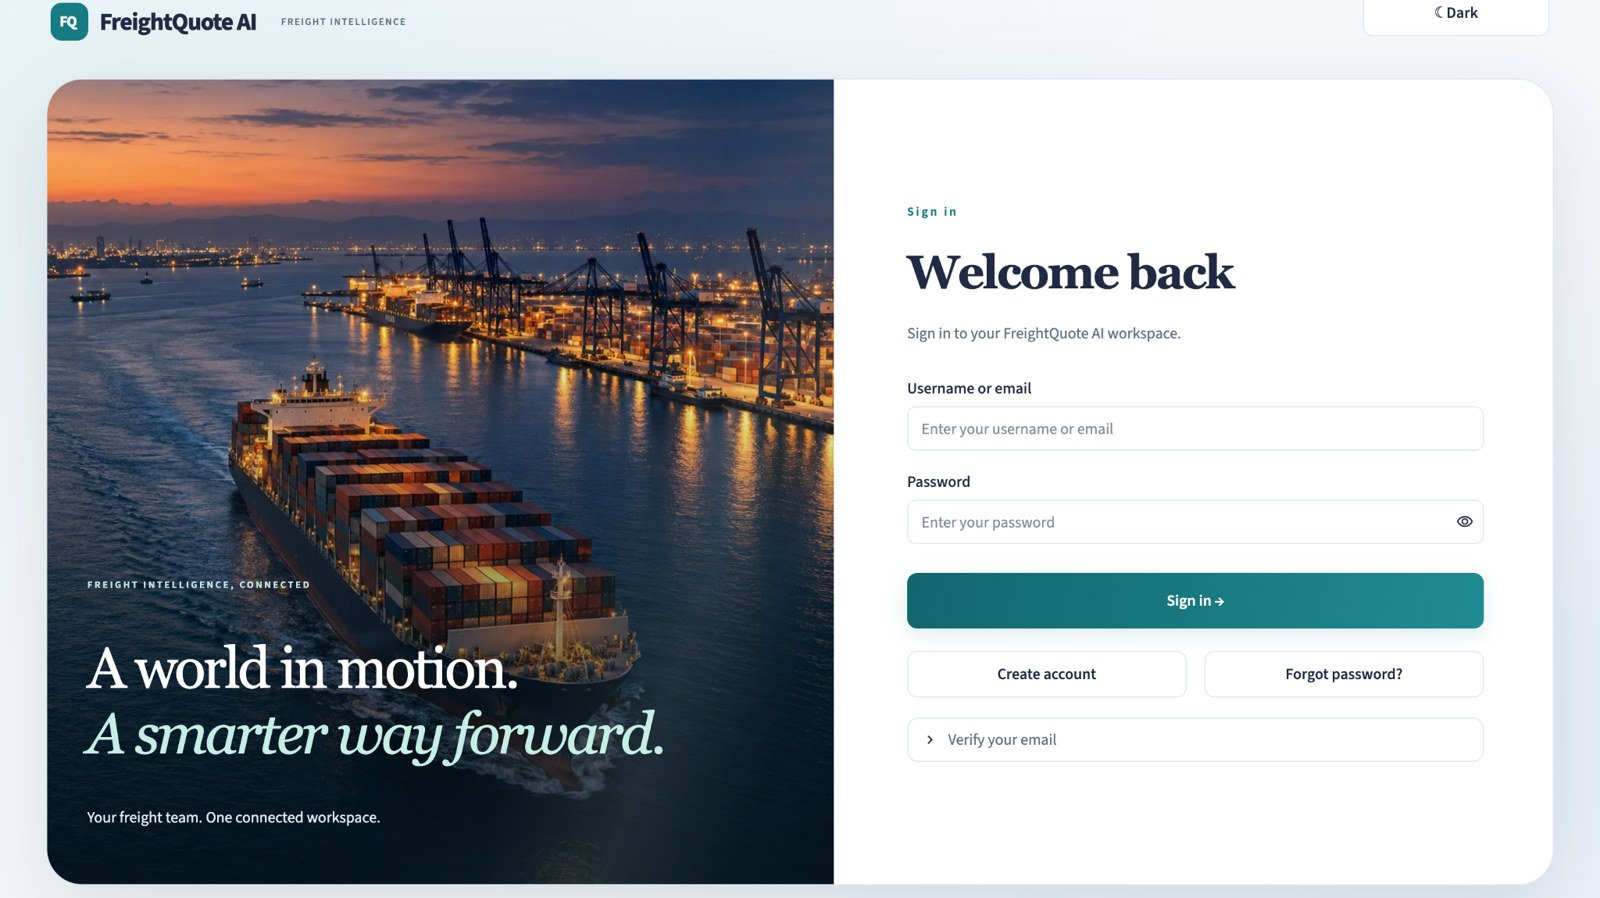



### 02. Account registration

The registration page collects username, email, password, confirmation, a fixed security question and its answer. New registrations are customers. The password guidance appears beside the form; the server applies validation when submitted.

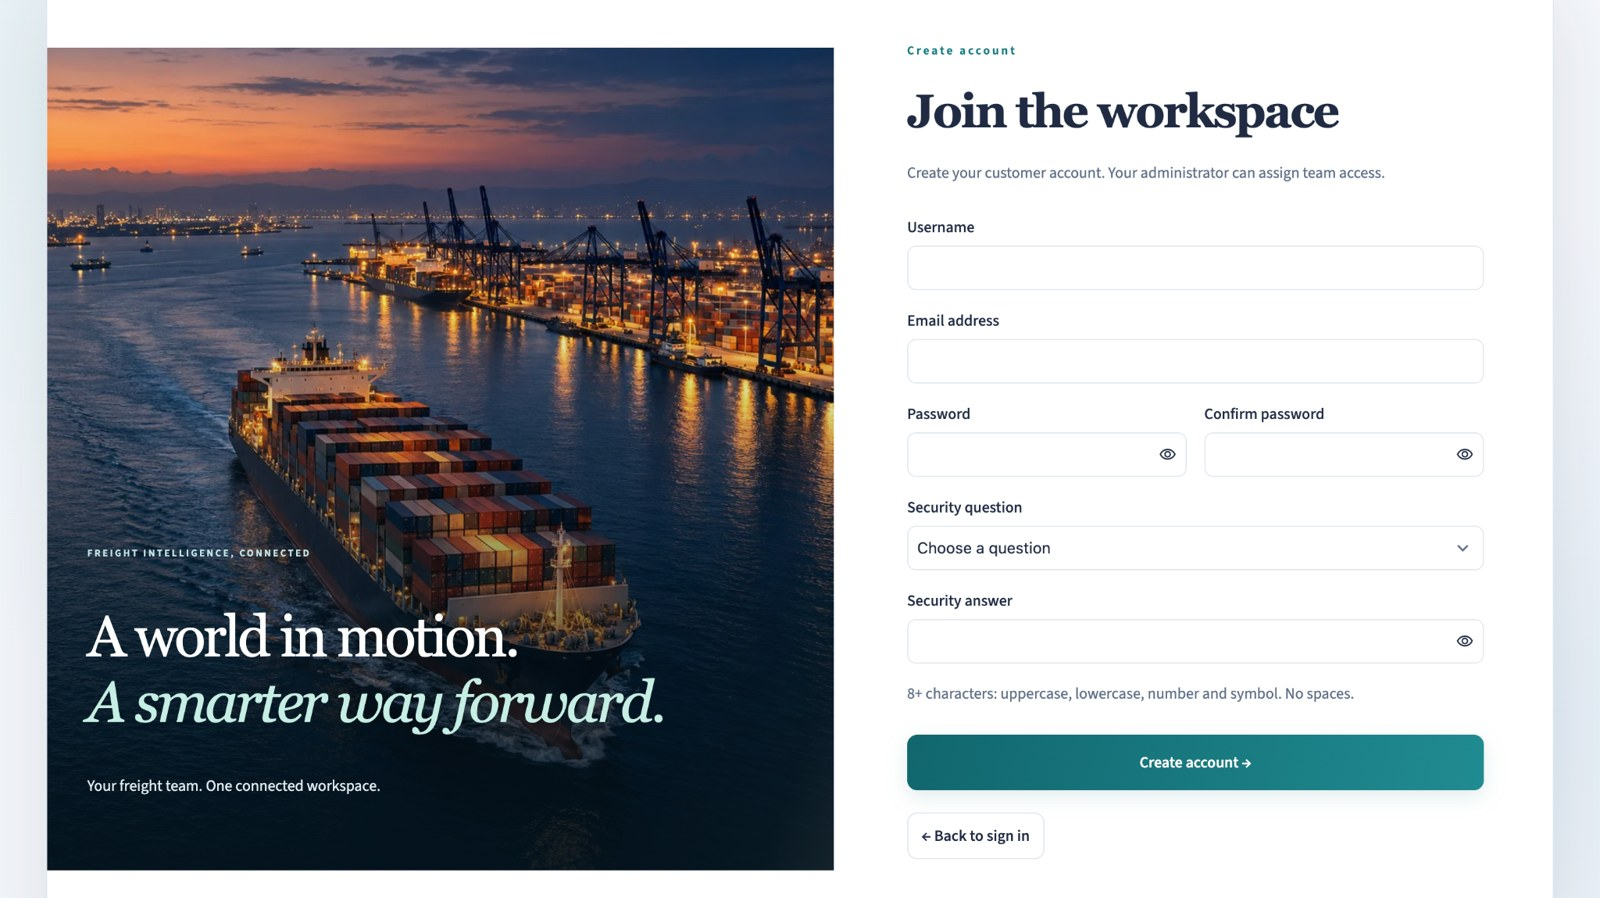



### 03. Email recovery — initial screen

Email OTP is selected as the recovery method. The user supplies the registered email before requesting a code. This capture documents the recovery form and its instructions, not successful delivery.

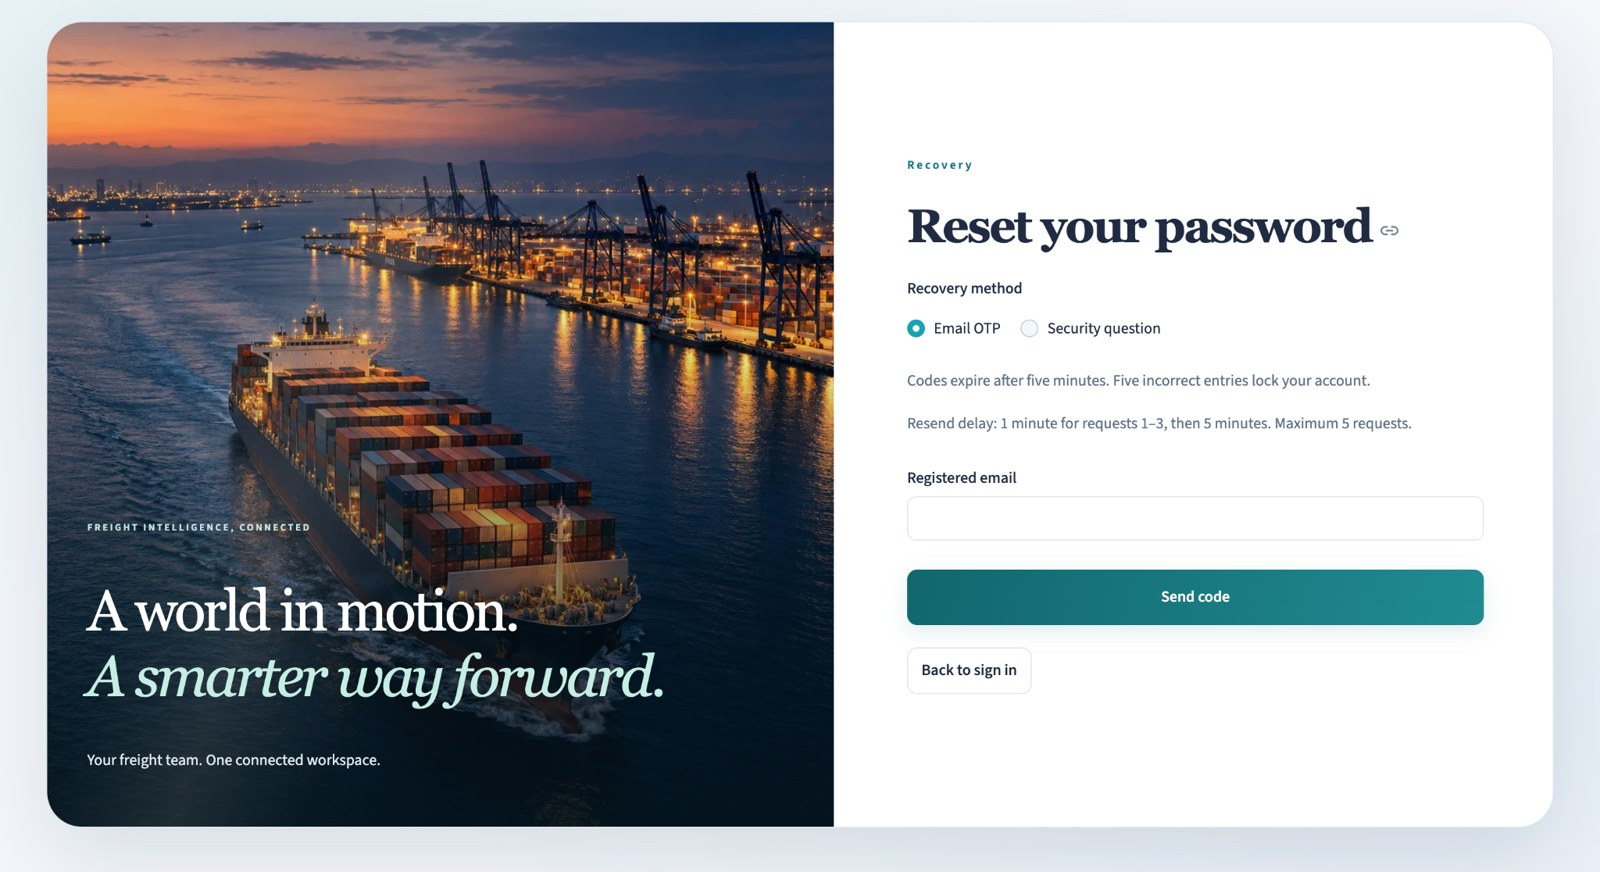



### 04. Signup email verification

The activation screen shows an account-created notice and the controls for requesting and checking an email code. Code expiry and resend availability are separate states. A user verifies their email before signing in; this is the application screen, not an inbox capture.

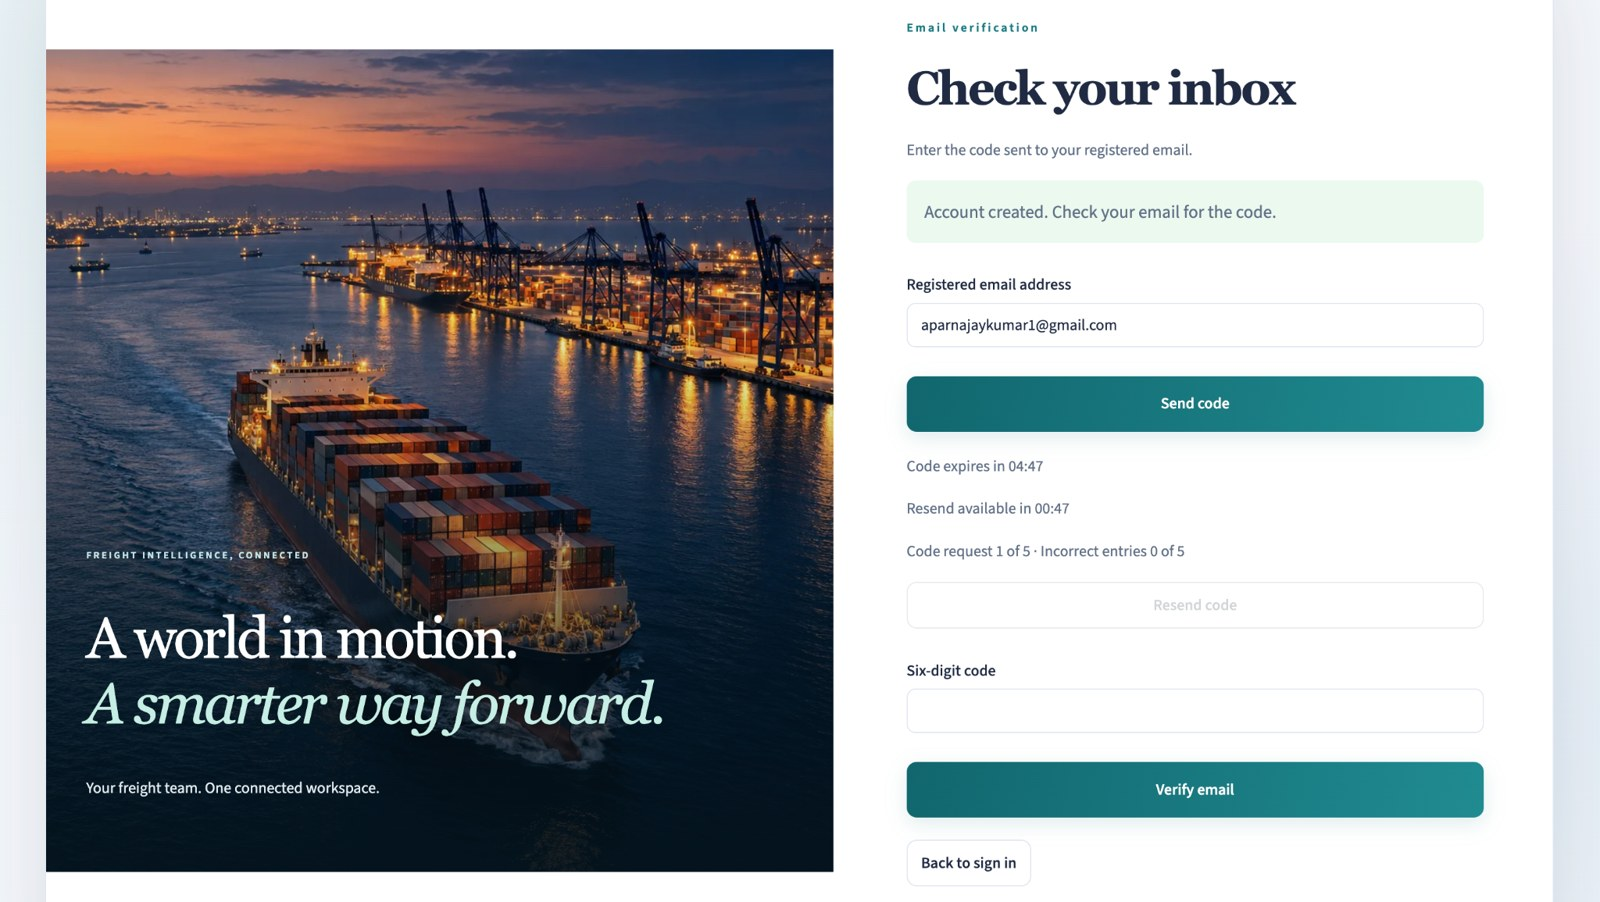



### 05. Recovery code entry

The email recovery flow has progressed to the code-entry stage. The screen includes expiry/resend information and a Verify code action. A correct code authorizes a short-lived password reset; it does not sign the user in directly.

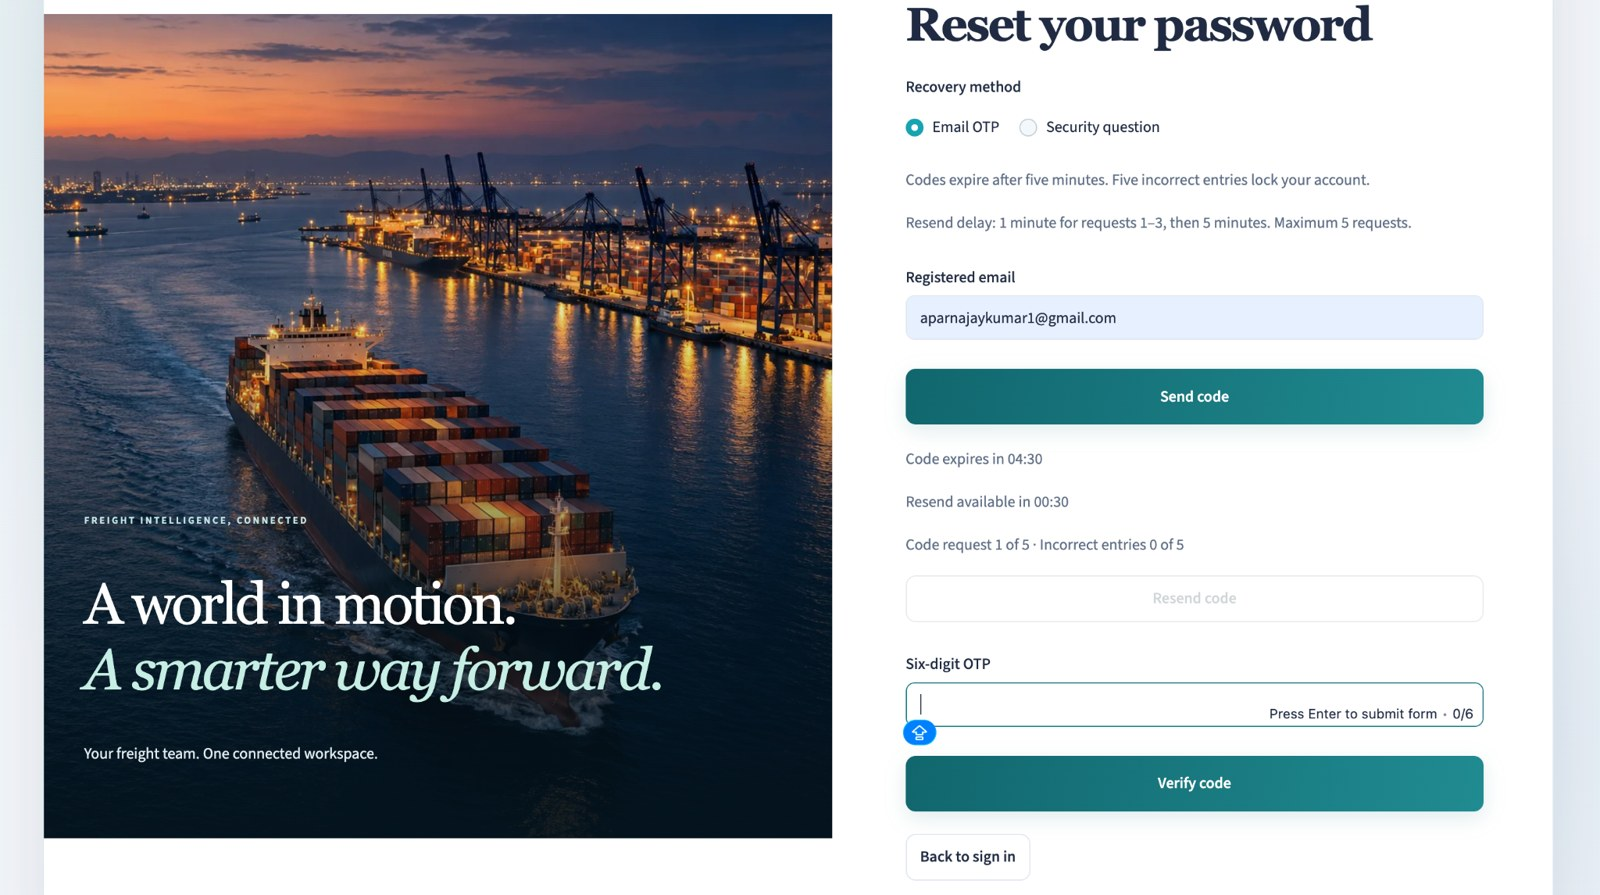



### 06. Customer workspace — light theme

The dashboard greets the signed-in customer and shows the assigned role, account status and remaining session time. Sidebar entries lead to the account profile and security settings. Freight cards are planned integrations, not evidence of a working quotation engine.

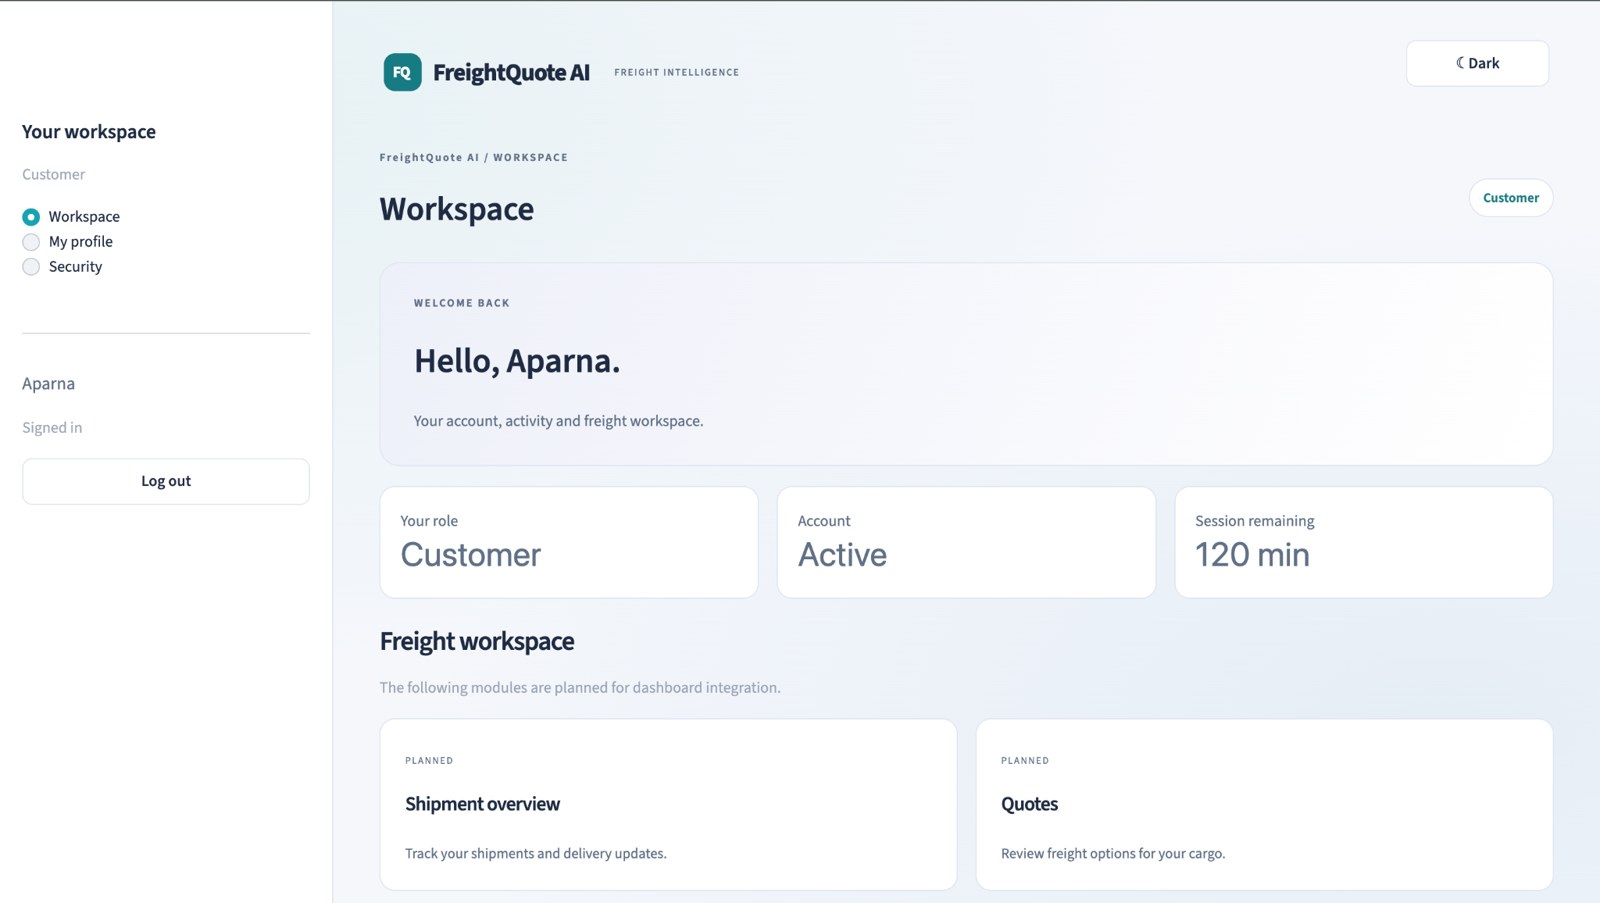



### 07. Customer workspace — dark theme

The same customer workspace is shown in dark mode. The role and session information remain visible. This documents theme coverage after login without changing account permissions.

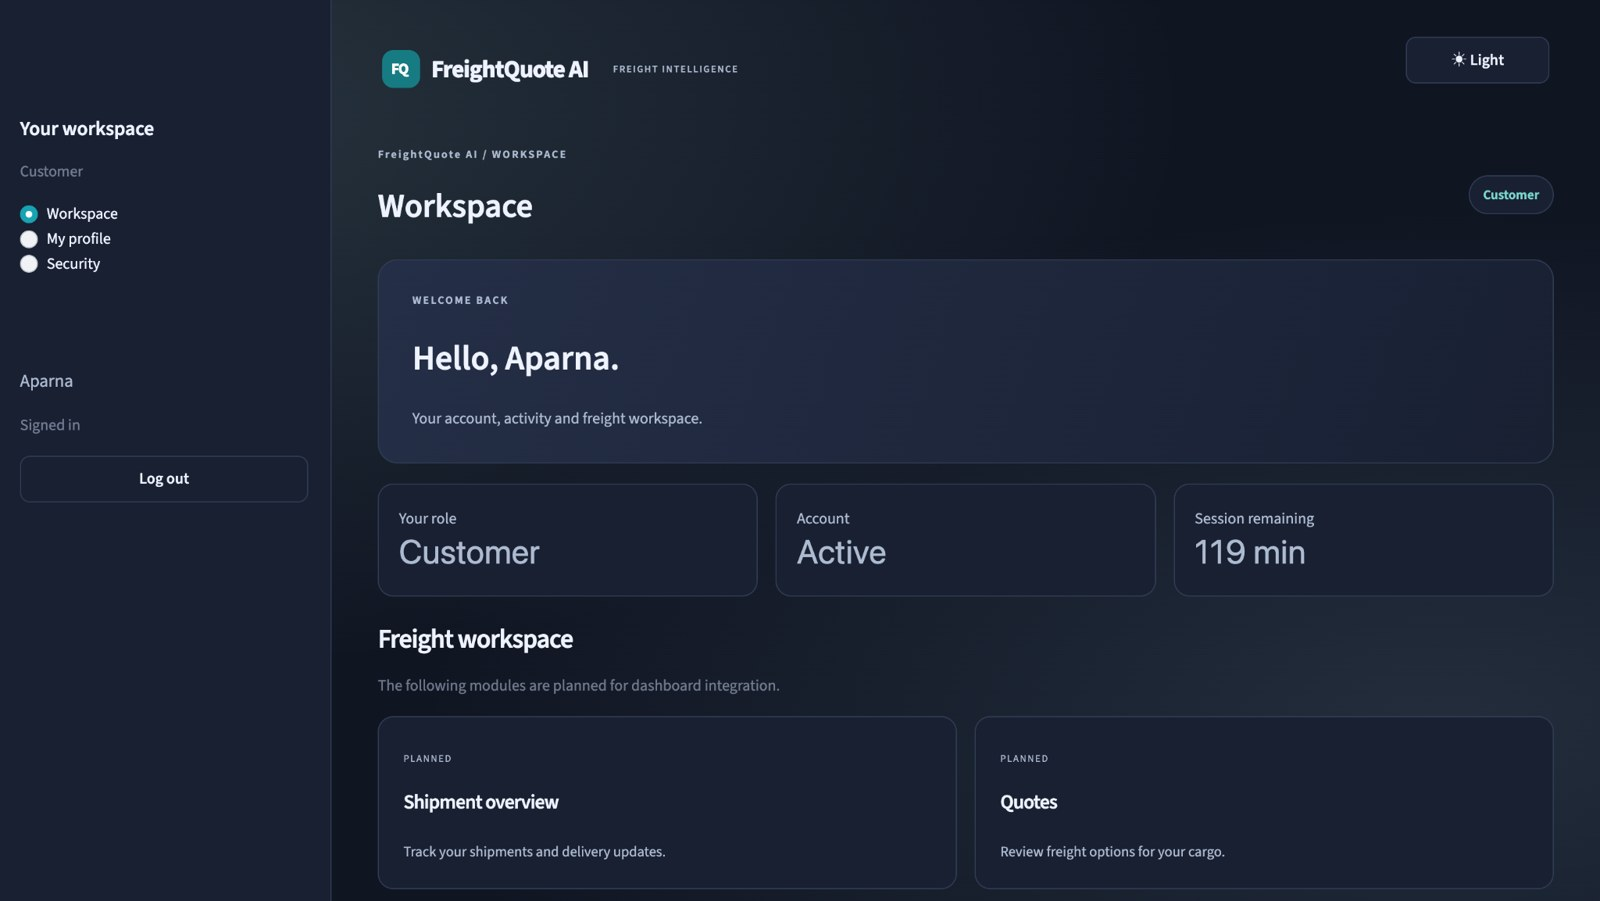



### 08. Security-question recovery — lookup

Security question is selected instead of Email OTP. The user enters the registered username and asks the application to retrieve the stored question. This is the first stage of the alternative recovery route.

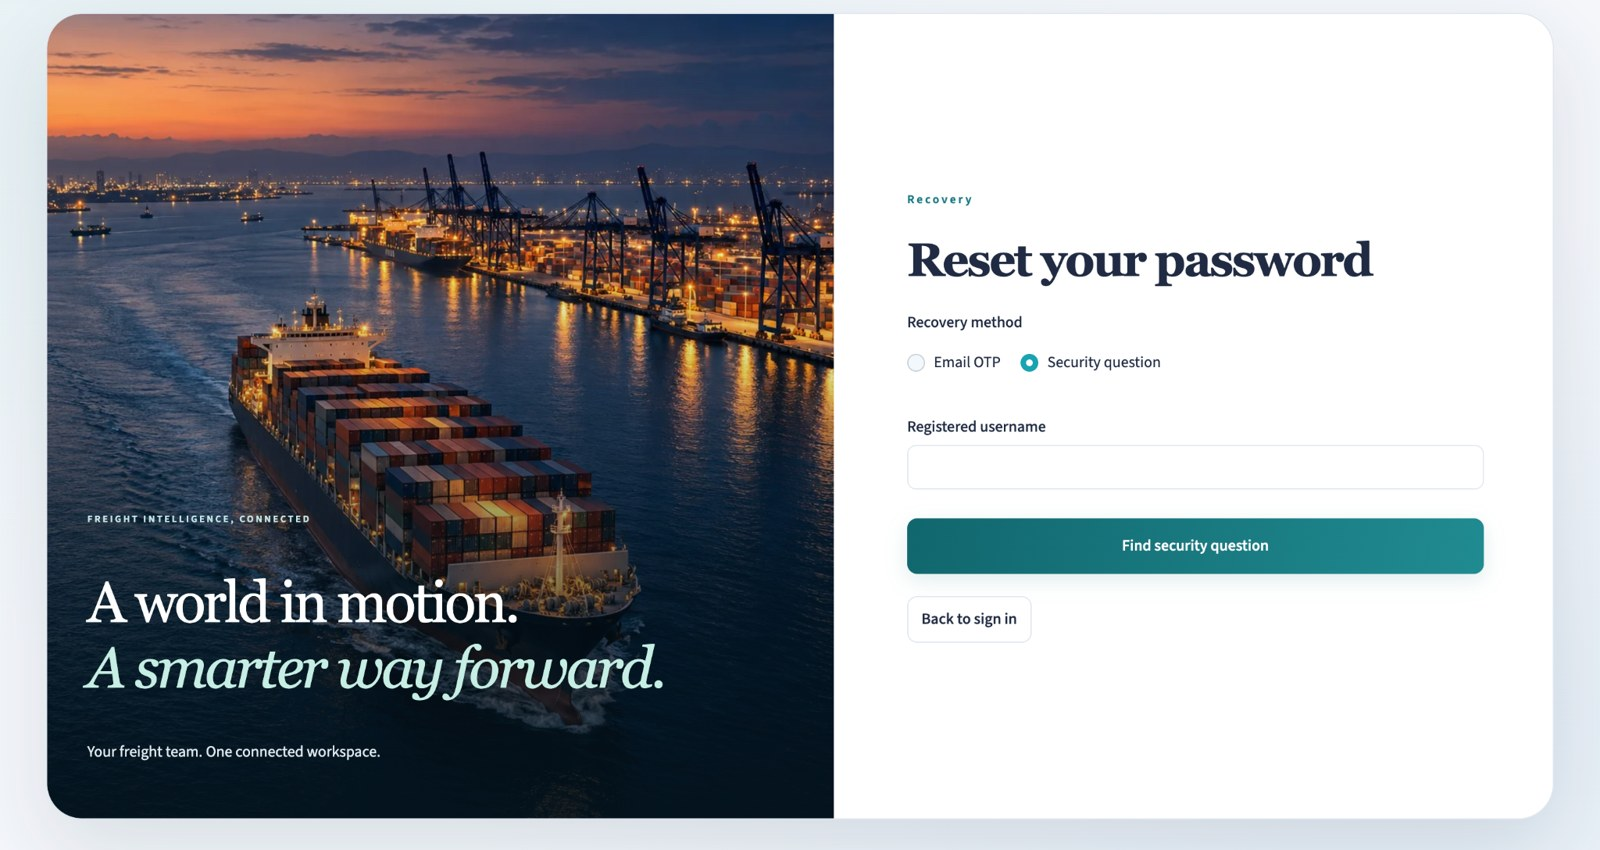



### 09. Security-question recovery — answer

The saved question is displayed with a masked answer field and a Verify answer button. A correct answer allows the password-reset stage. The image shows the answer-entry state, not the completion of a reset.

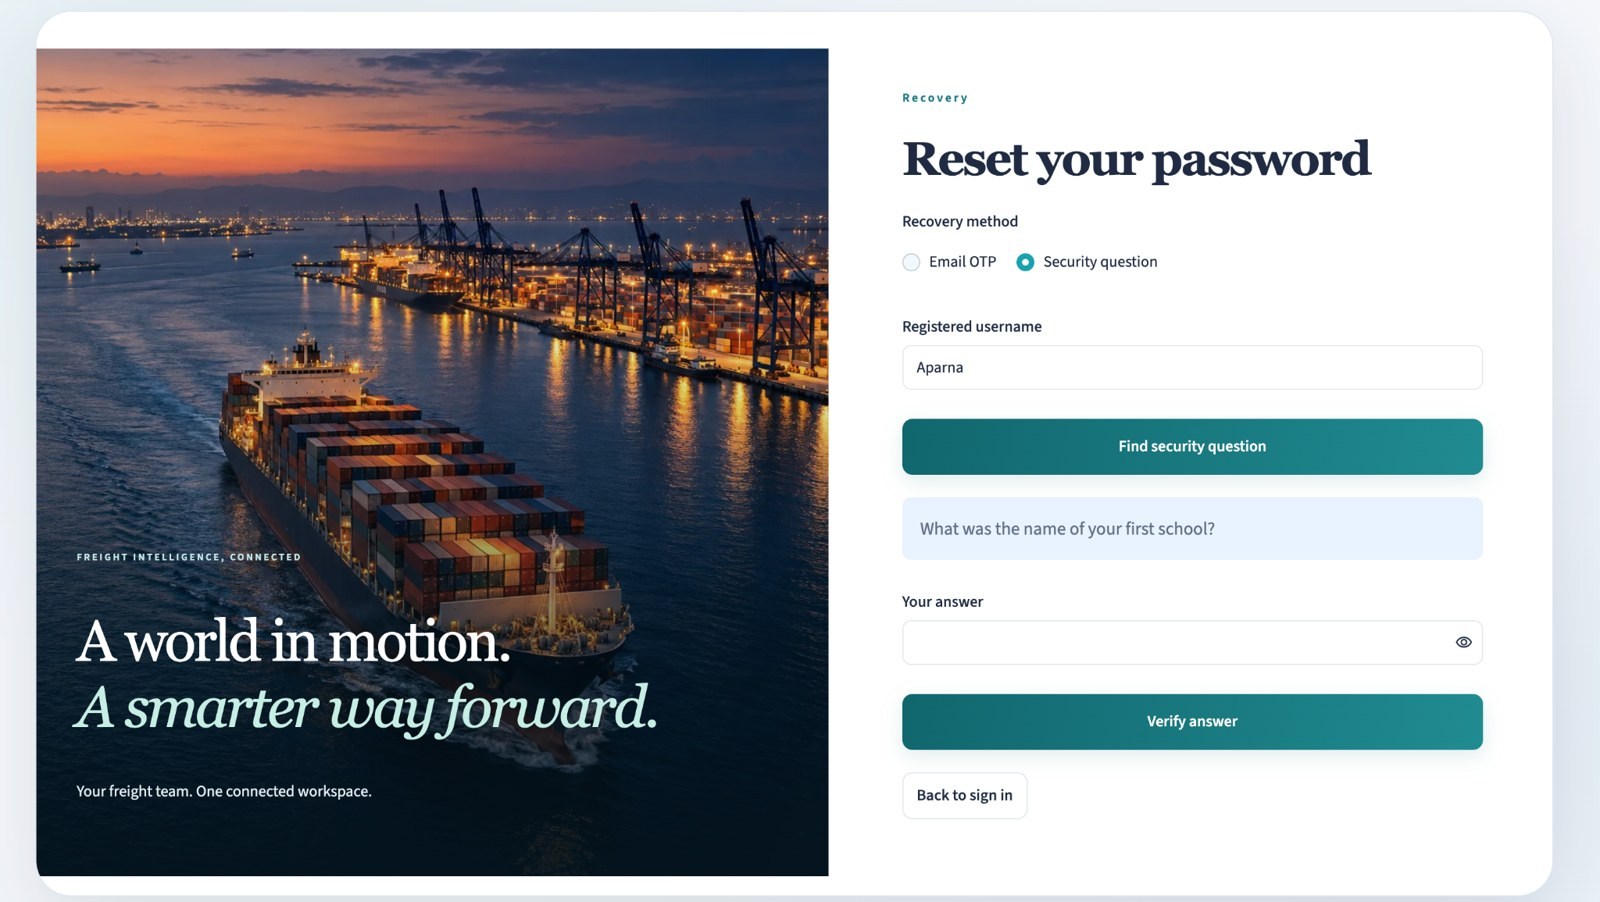



### 10. Administrator workspace — light theme

The configured administrator is signed in through the shared login. The sidebar includes User management and Audit trail in addition to normal account views. These extra entries reflect server-authorized admin access.

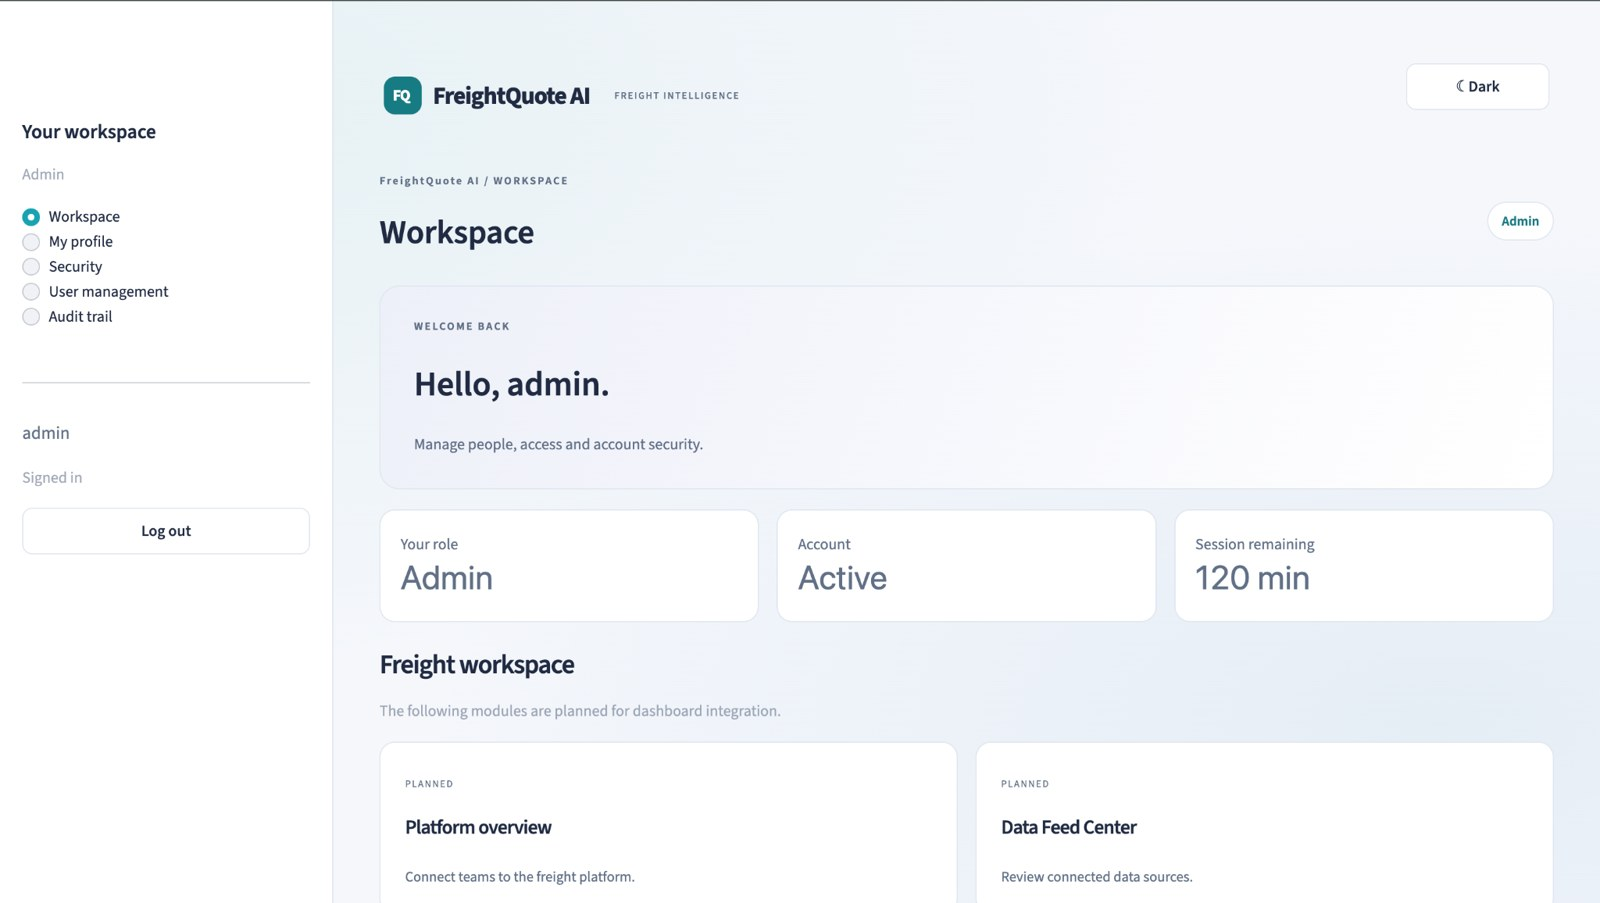



### 11. Administrator workspace — dark theme

The administrator workspace is displayed in dark mode. The role is Admin and the account is active. This confirms the visual treatment of the privileged workspace; the next captures show its management actions.

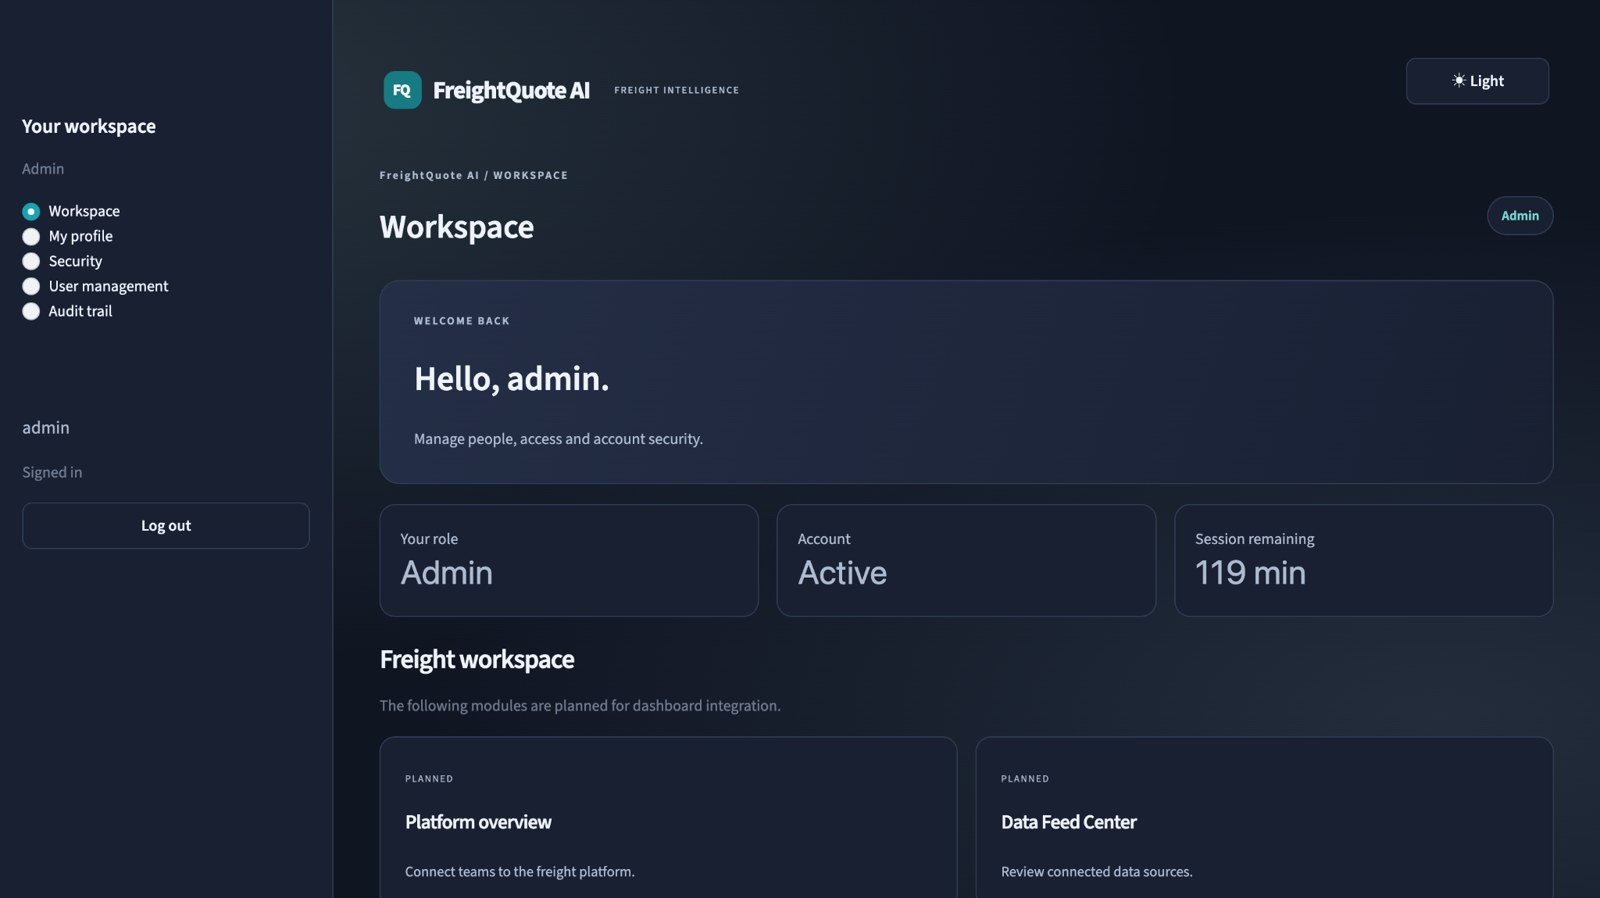



### 12. Recovery closed after account lock

The recovery screen has been replaced by a single account-locked notice and a return-to-sign-in action. OTP entry and resend controls are absent. The image records the locked state; the exact attempt threshold is verified by the implementation and tests.

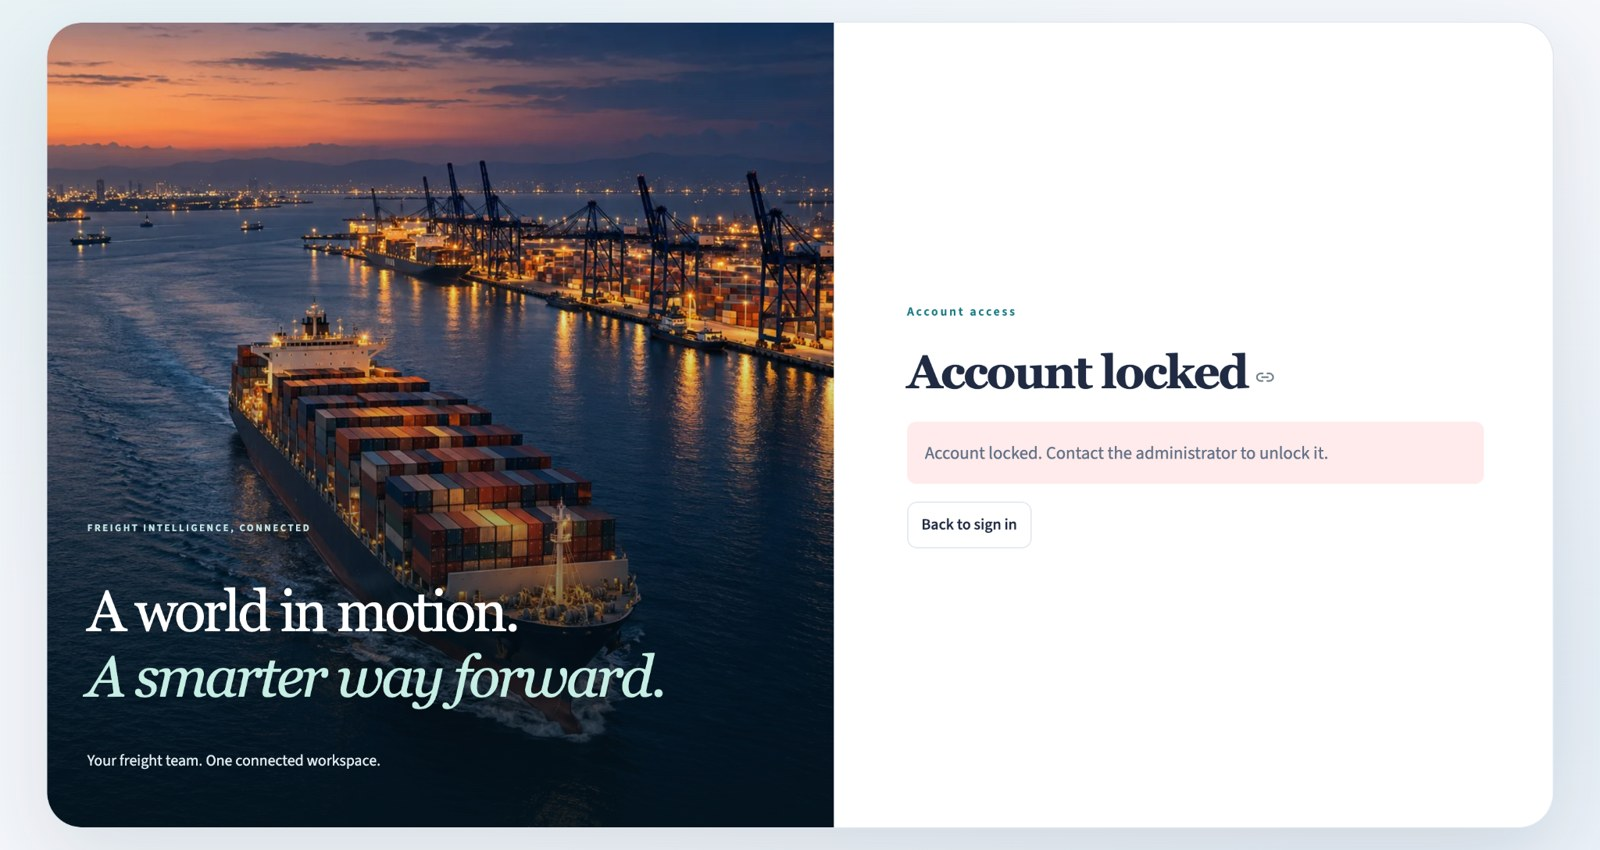



### 13. Sign-in rejected for a locked account

An attempt to sign in to the locked account produces an account-lock notice. Knowing the password does not bypass the lock. An administrator must unlock the account before the user can try again.

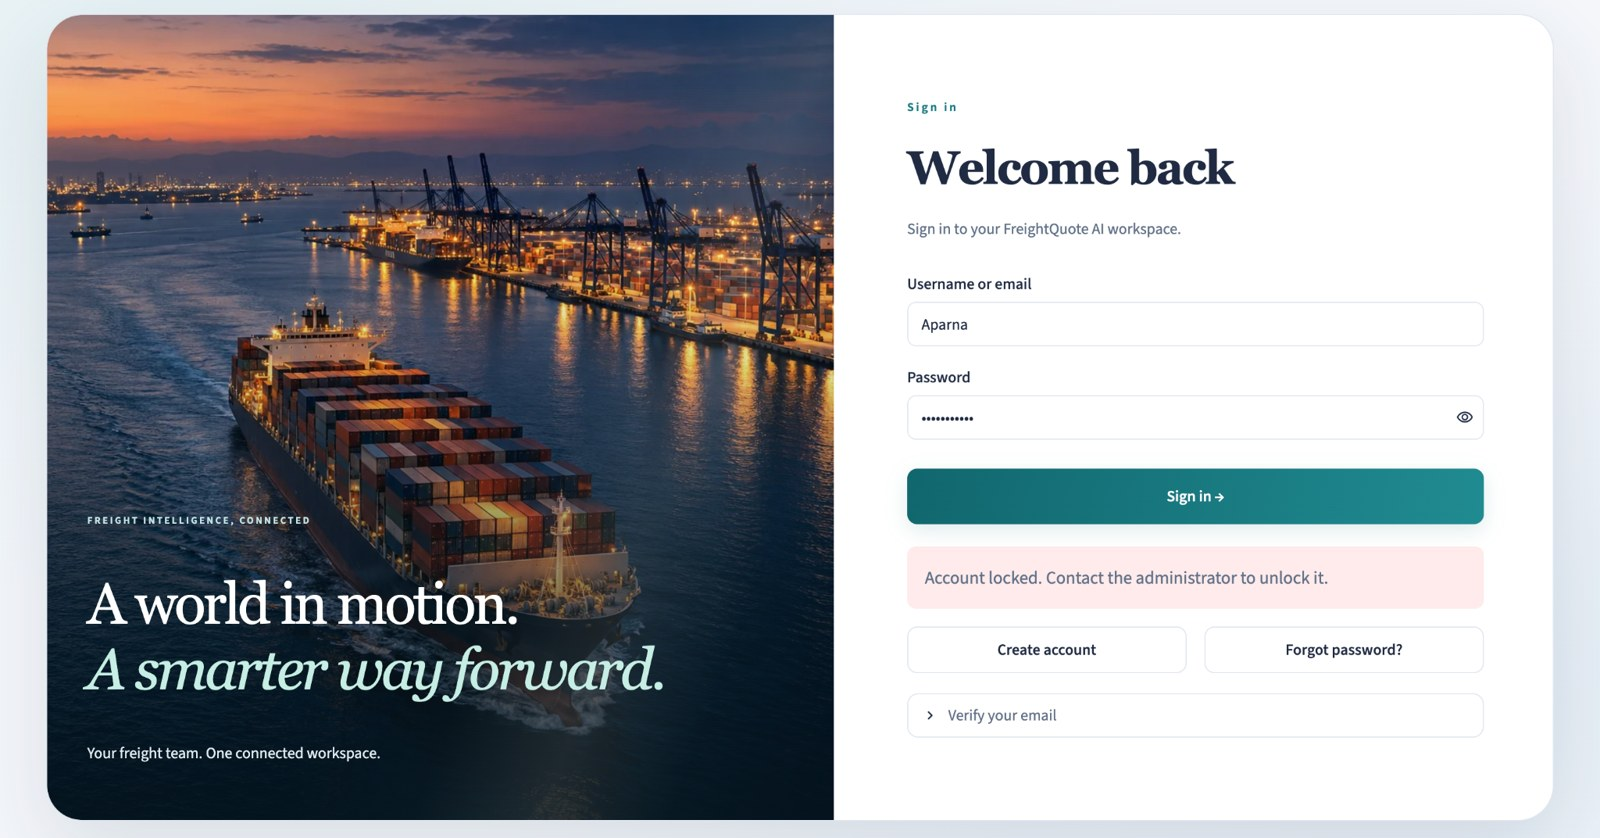



### 14. Registered-user directory

User management shows summary counts and a directory containing username, email, role and account state. The test account is locked in this capture. Password hashes, security-answer hashes and OTP values are not included in the table.

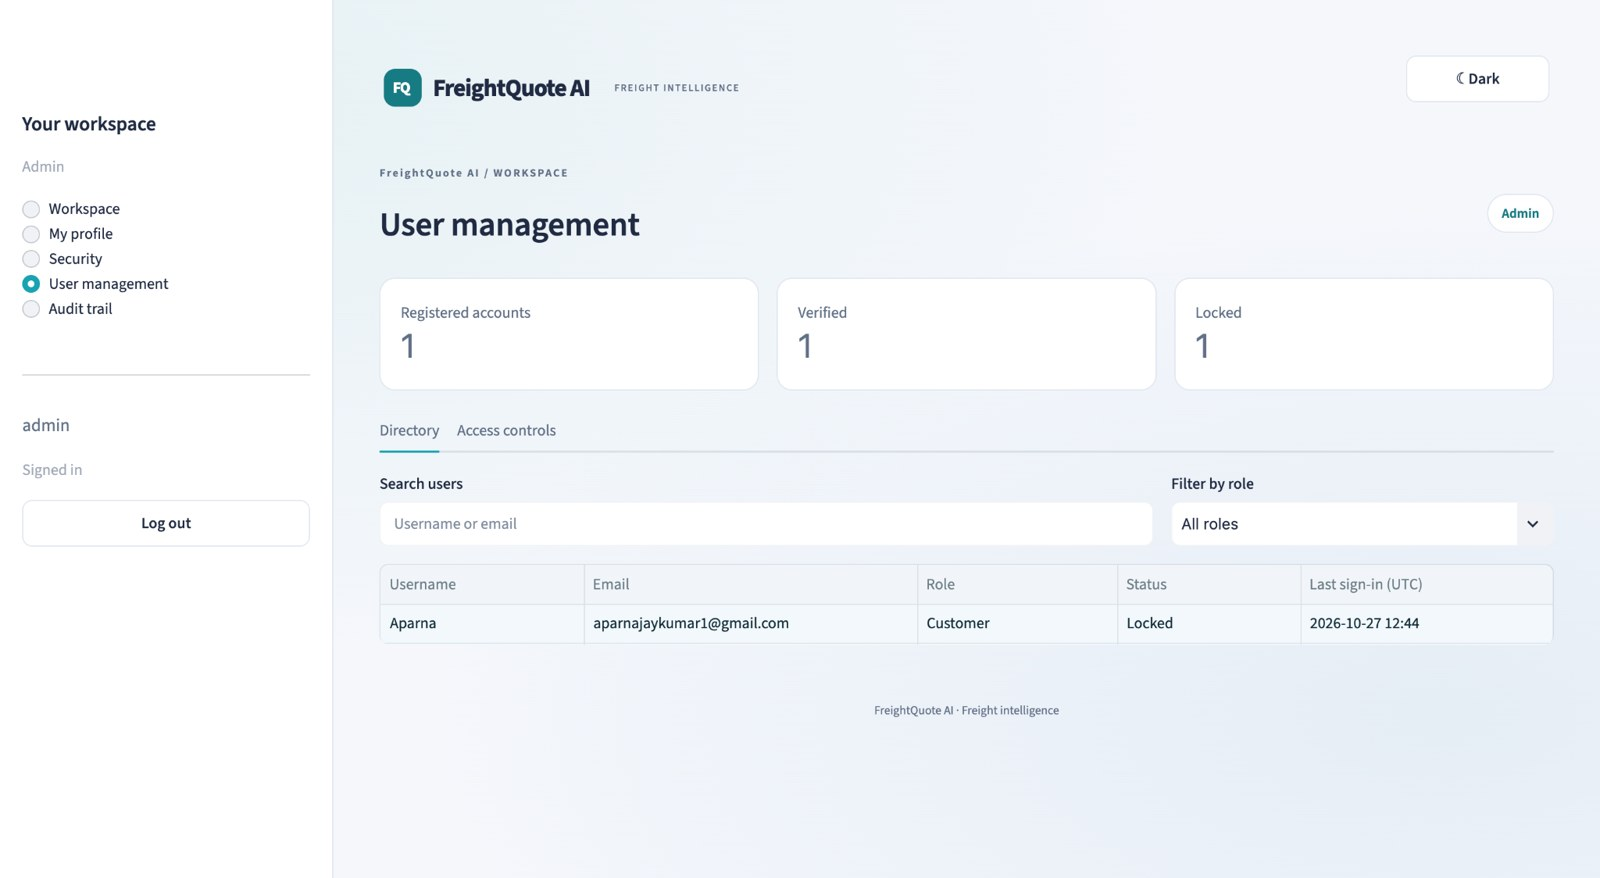



### 15. Administrator unlock action

The Access controls view offers a selector for a locked account and an Unlock account button. This operation is restricted to an authenticated administrator. Unlocking clears recovery counters and codes and invalidates old sessions.

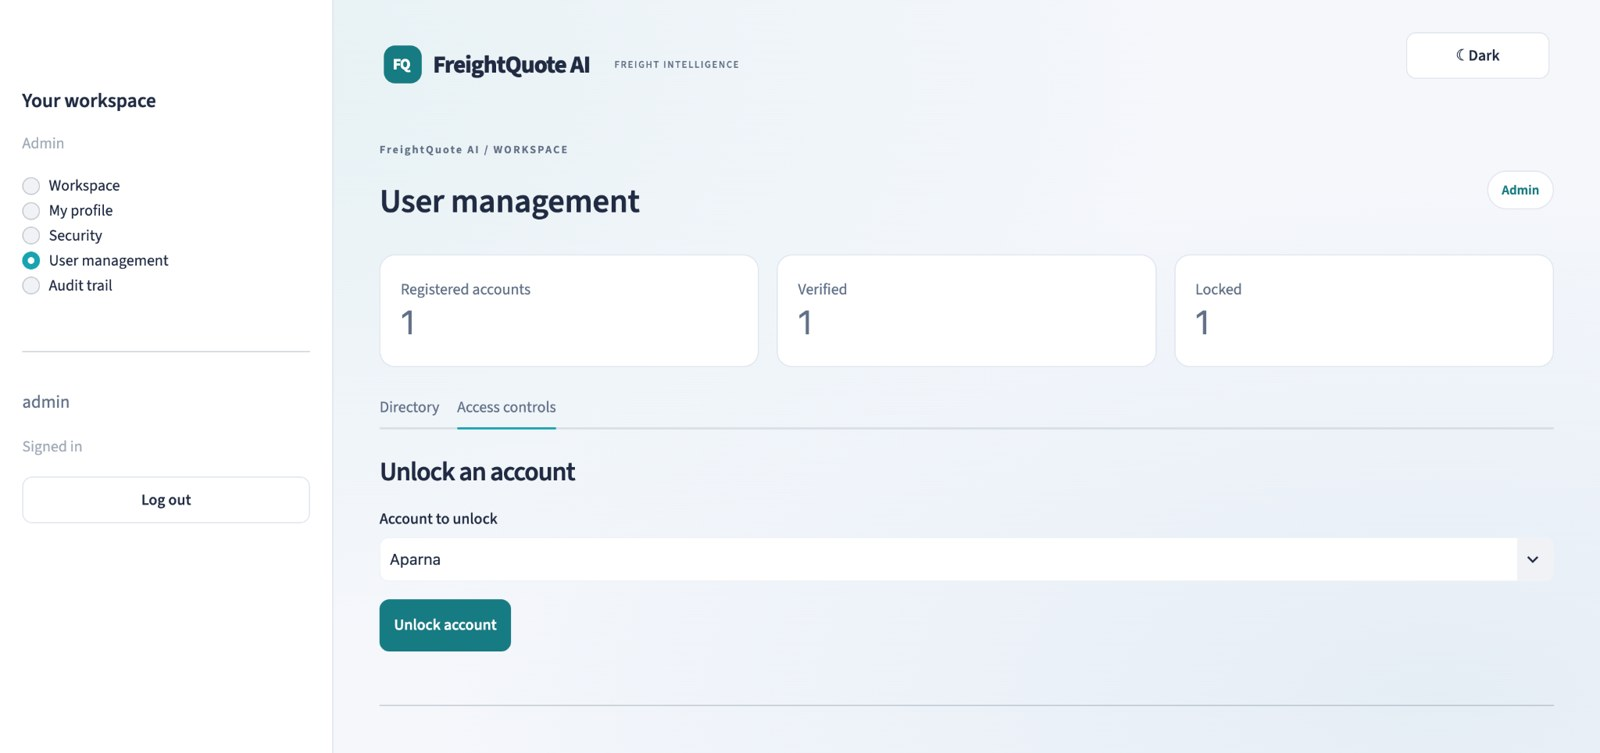



### 16. Account unlocked

A success notice appears and the locked-account count is now zero. The directory reflects the updated state. Together with the preceding image, this records the administrator unlock workflow.

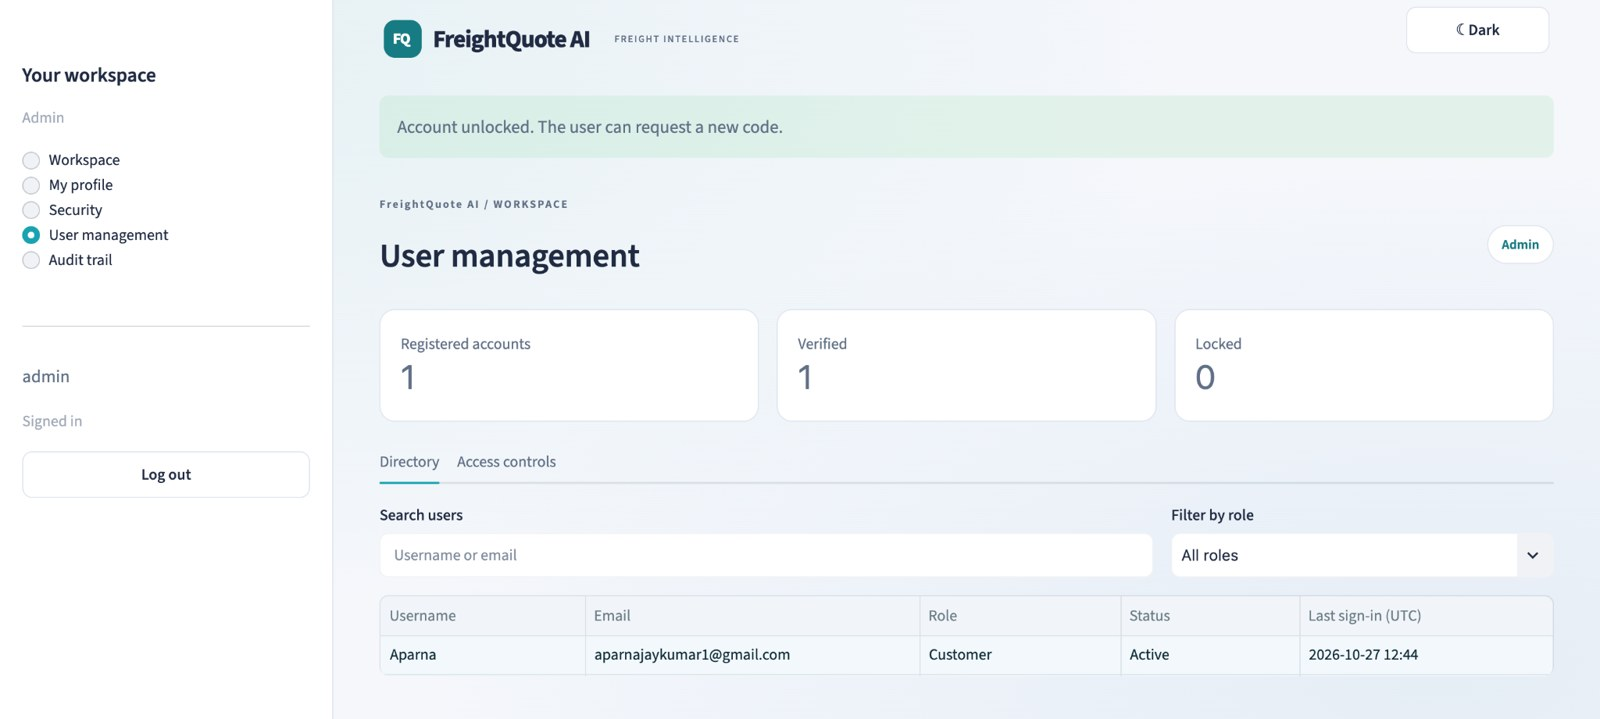



### 17. Available roles

The role dropdown shows Customer, Operations Manager, Freight Broker, Auditor and Admin. Role selection is an administrator action rather than a choice offered during signup. The list describes the roles supported by this milestone.

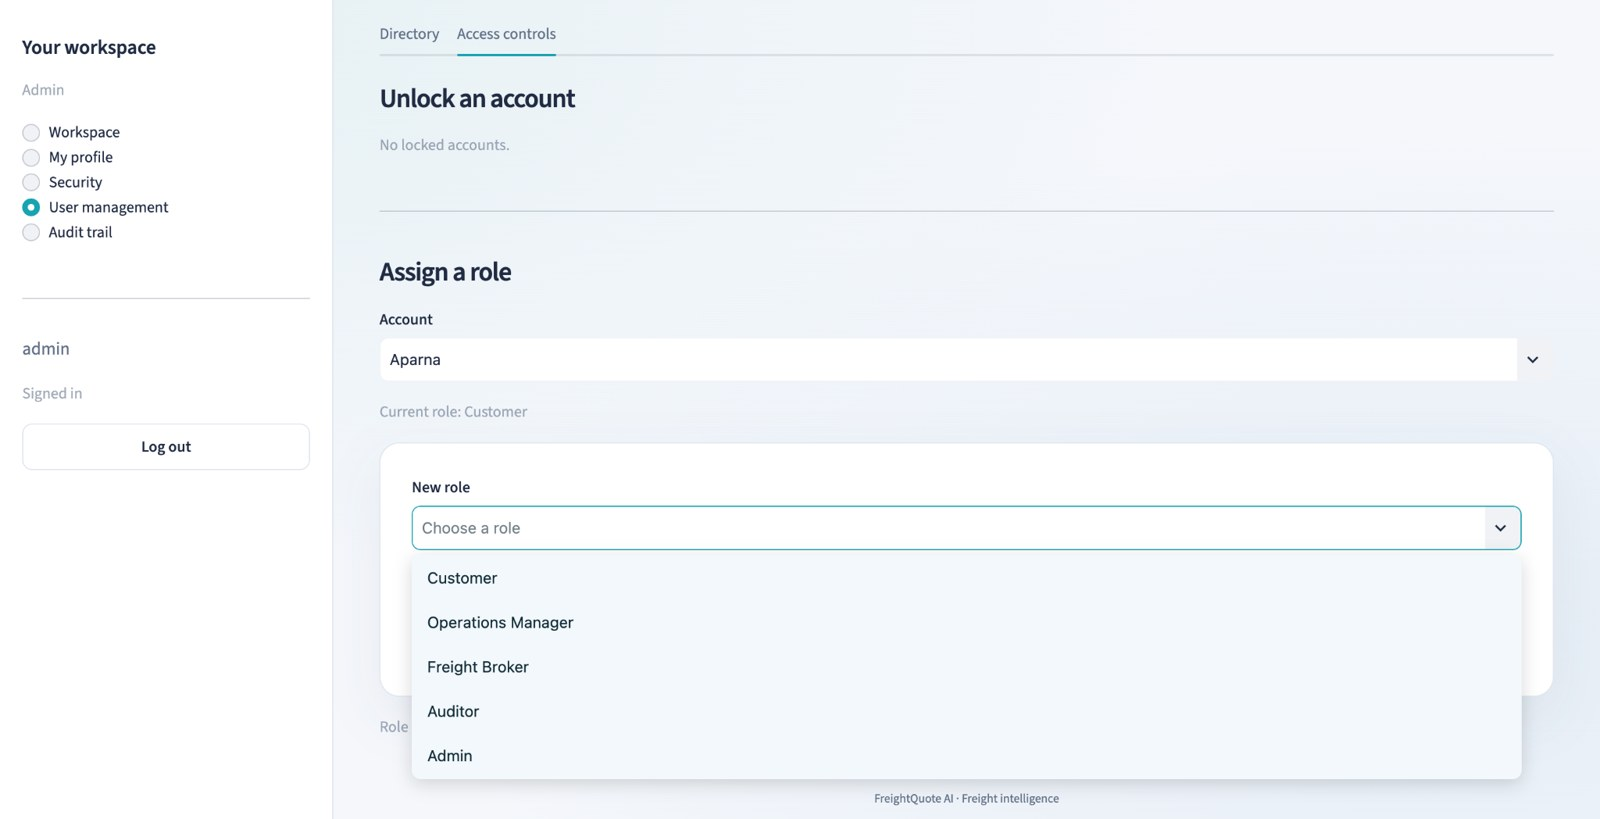



### 18. Preparing a role assignment

The account and requested role are selected, with confirmation and a Save role action. This is the assignment form before a demonstrated success notice. The screenshot alone does not prove the selected change was saved; the server enforces authorization and revokes existing sessions when a change succeeds.

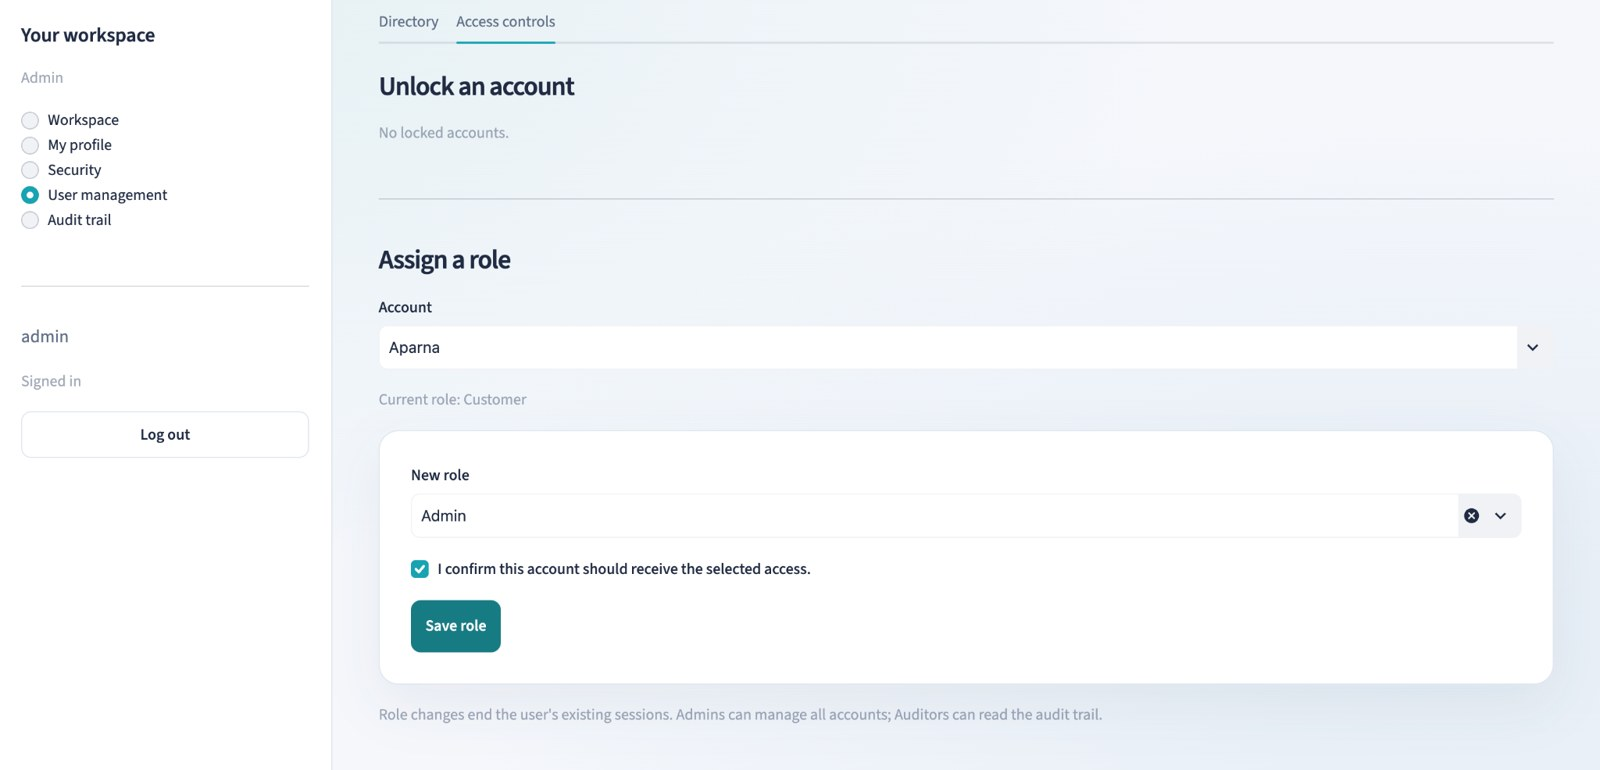



### 19. Shared login — dark theme

The final sign-in page is shown in dark mode with the freight photograph and themed controls. The layout retains the single-login entry point. The static image cannot demonstrate the short text entrance or the subtle photo sheen.

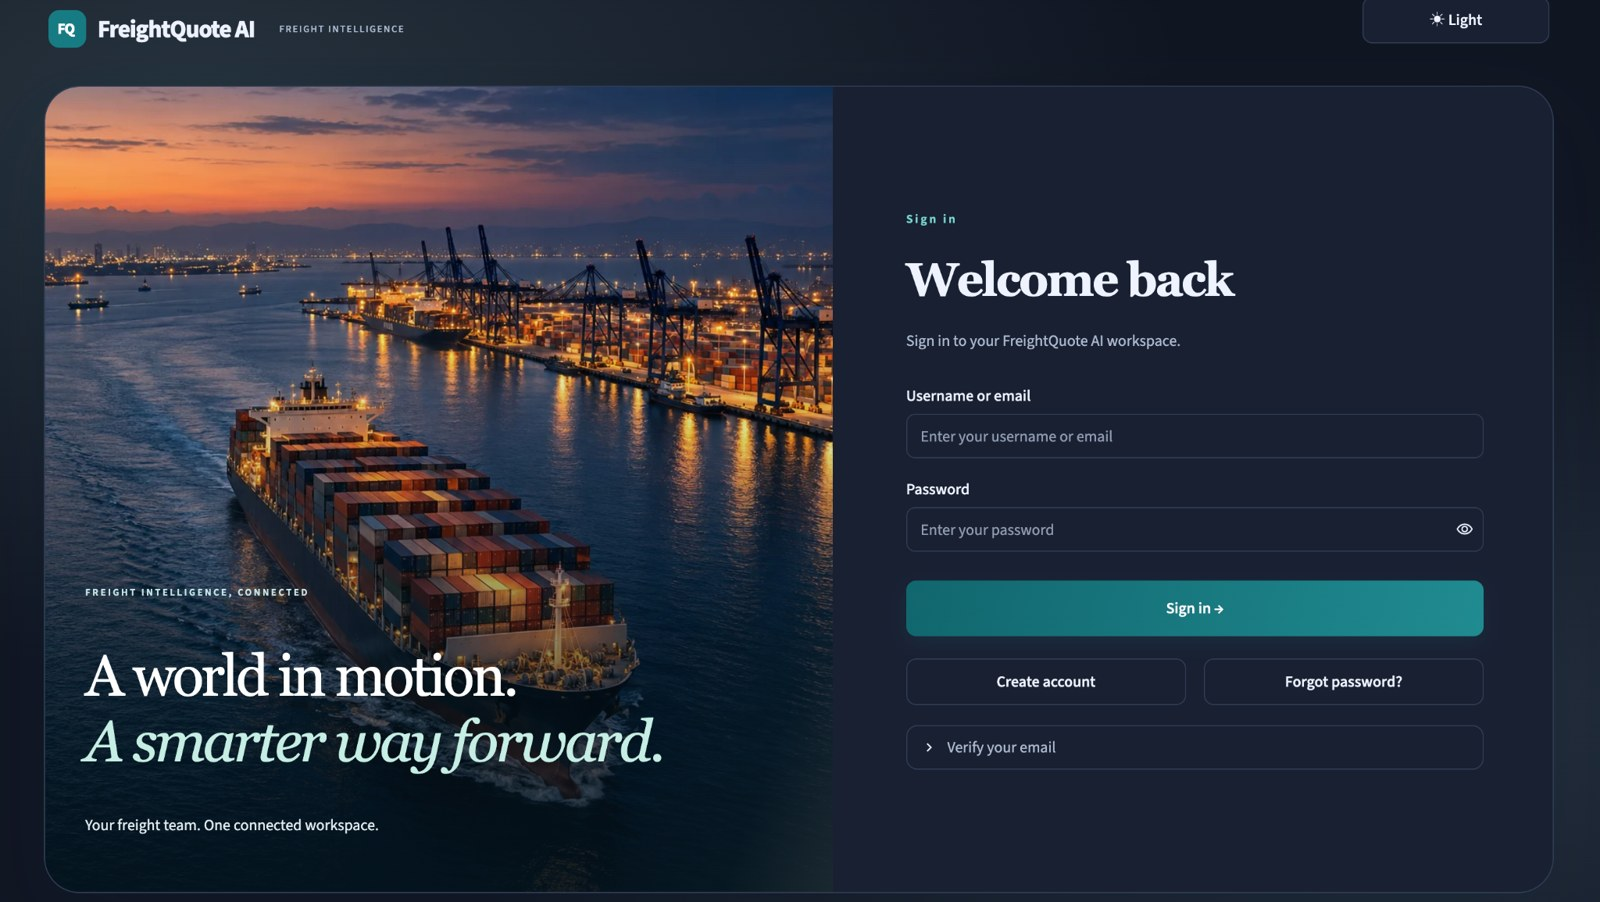




### 20. OTP email received in the inbox

The inbox capture shows a received FreightQuote AI email containing a six-digit one-time code. The message states that the code expires in five minutes and tells the recipient to ignore it if they did not request it. This provides the email-delivery evidence requested in the milestone, complementing the application code-entry screenshots. The capture demonstrates receipt of this message; code expiry, one-time use and lockout enforcement are handled by the backend and covered separately by tests.

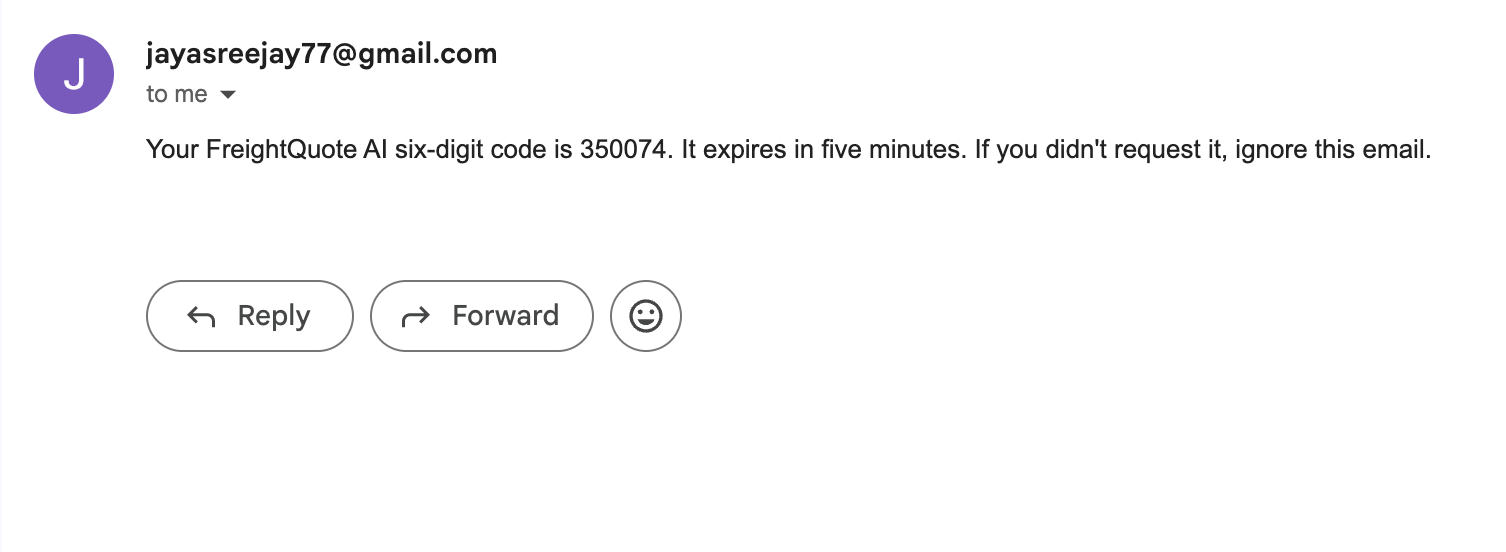
